# Figure 5: Rare QTL variants at disease genes

Rare-variant counts, ClinVar coverage, pathogenic-variant enrichment, and molecular effects at selected disease genes.


## Run the notebook

Use the R kernel. Start in the repository root. Set `QTL_INPUT_ROOT` to the
source result tables and `QTL_SUSIE_ROOT` to the separate fine-mapping tables.
Set `QTL_PAPER_ROOT` to the local reference directory and `QTL_SOURCE_ROOT`
to the figure checkout. Set these variables in R before running the cells.
Paths can contain spaces.

Run the cells from top to bottom. The cells show input reads, filters, joins,
counts, models, and plot construction. Intermediate objects stay in this R
session. New PDFs and PNGs go to
`notebook_outputs/`. The plotting scripts are in `notebooks/current/`.


## Source scripts

The processing steps below follow these preparation scripts. The source data are not included in Git.

- [fig5-select](../preparation/Fig5/select_all_assays.R): Select the rare all-assay rows and comparator-gene rows from raw SuSiE inputs and original ClinGen evidence.
- [fig5-main](../preparation/Fig5/prepare_main.R): Build A-E counts, ClinVar classes, population assignments, AR funnel, selected effects, and Fisher tests.

The notebook runs the processing in its own cells. The preparation guide lists the original input requirements and missing inputs.


## Setup

Validate the local input paths and load the plot libraries.


In [1]:
# Shared setup for the figure notebooks.
suppressPackageStartupMessages({
  library(tidyverse)
  library(patchwork)
})
if (requireNamespace("showtext", quietly = TRUE)) showtext::showtext_auto(FALSE)

paper_root <- Sys.getenv("QTL_PAPER_ROOT")
source_root <- Sys.getenv("QTL_SOURCE_ROOT", getwd())
input_root <- Sys.getenv("QTL_INPUT_ROOT", source_root)
susie_root <- Sys.getenv("QTL_SUSIE_ROOT", input_root)
repo_root <- getwd()
notebook_output <- Sys.getenv("QTL_NOTEBOOK_OUTPUT", file.path(getwd(), "notebook_outputs"))
input_records <- new.env(parent = emptyenv())

checked_input <- function(root, relative, variable) {
  if (!nzchar(root)) stop("Set ", variable, " before you run this notebook.", call. = FALSE)
  if (grepl("^(gs|s3|https?)://", root)) {
    stop("Input localization error: ", variable, " must be a local directory.", call. = FALSE)
  }
  if (grepl("[.]rds([.]gz)?$", relative, ignore.case = TRUE)) {
    stop("Saved RDS inputs are not used by these notebooks: ", relative, call. = FALSE)
  }
  path <- file.path(root, relative)
  if (!file.exists(path) || dir.exists(path) || file.access(path, 4) != 0) {
    stop("Missing or unreadable input: ", relative, ". Check ", variable, ".", call. = FALSE)
  }
  path <- normalizePath(path, mustWork = TRUE)
  key <- paste(variable, relative, sep = ":")
  hash <- unname(tools::md5sum(path))
  previous <- input_records[[key]]
  if (!is.null(previous) && !identical(previous$md5, hash)) {
    stop("Input changed during notebook execution: ", relative, call. = FALSE)
  }
  if (is.null(previous)) input_records[[key]] <- list(root = variable, path = relative, md5 = hash)
  path
}
paper_file <- function(relative) checked_input(paper_root, relative, "QTL_PAPER_ROOT")
source_file <- function(relative) checked_input(source_root, relative, "QTL_SOURCE_ROOT")
input_file <- function(relative) checked_input(input_root, relative, "QTL_INPUT_ROOT")
susie_file <- function(relative) checked_input(susie_root, relative, "QTL_SUSIE_ROOT")
repo_file <- function(relative) checked_input(repo_root, relative, "QTL_REPO_ROOT")
output_file <- function(relative) {
  path <- file.path(notebook_output, relative)
  dir.create(dirname(path), recursive = TRUE, showWarnings = FALSE)
  path
}

save_plot <- function(plot, name, width_mm = 180, height_mm = 130) {
  message("Export aggregate plot: ", name)
  for (extension in c("pdf", "png")) {
    ggplot2::ggsave(output_file(paste0(name, ".", extension)), plot,
                   width = width_mm, height = height_mm, units = "mm", dpi = 180,
                   device = if (extension == "pdf") grDevices::cairo_pdf else "png",
                   bg = "white", limitsize = FALSE)
  }
  invisible(plot)
}

display_image <- function(path) {
  capture <- getOption("qtl.notebook.display")
  if (is.function(capture)) capture(path) else IRdisplay::display_png(file = path)
  invisible(NULL)
}
show_reference <- function(number) {
  path <- paper_file(paste0("output/Science_submission_package_20261102/Figures/Figure", number, ".png"))
  message("Display reference Figure ", number, ".")
  display_image(path)
}

theme_set(theme_classic(base_size = 9) +
            theme(plot.title = element_blank(), plot.subtitle = element_blank(),
                  legend.title = element_blank(), panel.grid = element_blank()))
options(repr.plot.width = 10, repr.plot.height = 7, repr.plot.res = 150)
message("Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.")
# Local source-result inputs and memory-only intermediate objects.
prep_root <- function(name) {
  value <- switch(name, paper = paper_root, source = source_root,
                  input = input_root, susie = susie_root,
                  stop("Unknown source root: ", name, call. = FALSE))
  if (!nzchar(value)) stop("Set the local ", name, " root before running the notebook.", call. = FALSE)
  value
}
.prep_root <- prep_root
prep_input <- function(root_name, relative) {
  variable <- c(paper = "QTL_PAPER_ROOT", source = "QTL_SOURCE_ROOT",
                input = "QTL_INPUT_ROOT", susie = "QTL_SUSIE_ROOT")[[root_name]]
  checked_input(prep_root(root_name), relative, variable)
}
prep_input_any <- function(root_name, candidates) {
  for (relative in candidates) {
    if (file.exists(file.path(prep_root(root_name), relative))) return(prep_input(root_name, relative))
  }
  stop("Missing source input under ", root_name, ": ", paste(candidates, collapse = ", "), call. = FALSE)
}
prep_input_file <- function(variable, fallback_root = "input", relative) {
  path <- Sys.getenv(variable)
  if (!nzchar(path)) return(prep_input_any(fallback_root, relative))
  checked_input(dirname(path), basename(path), paste0("env:", variable))
}
# Resolve recorded paths for the input-unchanged check. Records contain no
# machine-specific directory names; explicit file overrides retain their key.
recorded_input_path <- function(record) {
  if (startsWith(record$root, "env:")) return(Sys.getenv(sub("^env:", "", record$root)))
  root <- switch(record$root, QTL_PAPER_ROOT = paper_root,
                 QTL_SOURCE_ROOT = source_root, QTL_INPUT_ROOT = input_root,
                 QTL_SUSIE_ROOT = susie_root, QTL_REPO_ROOT = repo_root,
                 stop("Unknown recorded input root: ", record$root, call. = FALSE))
  file.path(root, record$path)
}

# These functions read the tracked result-table manifest. Each notebook starts
# with an empty memory store. An existing file cannot skip a calculation.
prep_result_runtime <- function(figure, envir = parent.frame()) {
  manifest <- readr::read_tsv(repo_file(file.path(figure, "inputs.tsv")),
    col_types = cols(.default = col_character()), na = c("", "-"), show_col_types = FALSE)
  computed <- new.env(parent = emptyenv())
  input_files <- function(key) {
    rows <- manifest[manifest$key == key, , drop = FALSE]
    if (!nrow(rows)) stop("Unknown result-table key: ", key, call. = FALSE)
    rows$path <- map_chr(rows$local_subpath, function(relative) {
      if (key == "clingen") {
        files <- list.files(file.path(prep_root("input"), relative), pattern = "[.]parquet$", full.names = FALSE)
        if (!length(files)) stop("No ClinGen parquet input under ", relative, call. = FALSE)
        return(prep_input("input", file.path(relative, sort(files)[1])))
      }
      candidates <- unique(c(relative, sub("splicing_SusieMerged[.]annotated", "splicing_SusieMerged..annotated", relative)))
      prep_input_any("input", candidates)
    })
    rows
  }
  input_path <- function(key) {
    rows <- input_files(key)
    if (nrow(rows) != 1L) stop("Expected one input for ", key, call. = FALSE)
    rows$path
  }
  load_input <- function(key, reader = data.table::fread, ..., attach_meta = TRUE) {
    rows <- input_files(key)
    metadata <- setdiff(names(rows), c("key", "local_subpath", "gs_uri", "source_repo", "source_workflow", "path"))
    map_dfr(seq_len(nrow(rows)), function(i) {
      data <- as_tibble(reader(rows$path[i], ...))
      if (attach_meta) for (column in metadata) if (!is.na(rows[[column]][i])) data[[column]] <- rows[[column]][i]
      data
    })
  }
  build_or_cache <- function(name, expr, refresh = FALSE) {
    if (!refresh && exists(name, envir = computed, inherits = FALSE)) return(computed[[name]])
    message("Calculate ", figure, "/", name, " from source result tables")
    value <- force(expr)
    computed[[name]] <- value
    value
  }
  for (name in c("input_files", "input_path", "load_input", "build_or_cache")) assign(name, get(name), envir = envir)
  invisible(computed)
}


Current figure setup loaded. Inputs are read in place; outputs use notebook_outputs/.


## Variant selection functions

Define the inheritance, ClinVar, ancestry, filtering, and distinct-count rules.


In [2]:
# Pure transformations from the accepted Figure 5 preparation scripts.
# See provenance.json for the original scripts and their checksums.
fig5_populations <- c("afr", "amr", "eas", "eur", "mid", "sas")
fig5_af_columns <- paste0("gvs_", fig5_populations, "_af")

fig5_reference <- function(reference) {
  reference %>%
    filter(confidence %in% c("Strong", "Definitive")) %>%
    select(targetId, targetFromSourceId, allelicRequirements) %>%
    unnest(allelicRequirements) %>% distinct()
}

fig5_clinvar_class <- function(classification) {
  classification <- replace_na(str_to_lower(str_trim(classification)), "")
  case_when(classification == "" ~ "Unannotated",
    str_detect(classification, "pathogenic") ~ "P/LP",
    str_detect(classification, "uncertain") ~ "VUS",
    str_detect(classification, "benign") ~ "B/LB", TRUE ~ "Other")
}

fig5_select_pairs <- function(raw, reference) {
  raw %>%
    mutate(gene = str_extract(molecular_trait_id, "ENSG[0-9]+"),
      clinvar_classification = replace_na(clinvar_classification, "")) %>%
    filter(gvs_max_af < 0.01, gene %in% reference$targetId) %>% distinct()
}

fig5_assign_populations <- function(frequencies) {
  frequencies <- frequencies %>% select(variant, all_of(fig5_af_columns)) %>% distinct()
  stopifnot(!anyDuplicated(frequencies$variant),
    all(complete.cases(frequencies)),
    all(as.matrix(frequencies[fig5_af_columns]) >= 0),
    all(as.matrix(frequencies[fig5_af_columns]) <= 1))
  result <- frequencies %>%
    pivot_longer(all_of(fig5_af_columns), names_to = "population", values_to = "af") %>%
    mutate(population = str_remove_all(population, "gvs_|_af"),
      population = factor(population, levels = fig5_populations)) %>%
    arrange(variant, population) %>% group_by(variant) %>%
    summarise(max_six_af = max(af), eur_af = af[population == "eur"],
      population_A = as.character(population[which.max(af)]),
      tied_max = sum(af == max(af)),
      tied_populations = paste(as.character(population[af == max(af)]), collapse = ";"),
      .groups = "drop") %>%
    mutate(eur_comparable = eur_af >= 0.75 * max_six_af,
      population_B = if_else(eur_comparable, "eur", population_A),
      reassigned_in_B = population_B != population_A)
  stopifnot(all(result$max_six_af > 0))
  result
}

fig5_variant_assignments <- function(pairs, frequencies, reference = NULL) {
  if (!is.null(reference)) {
    pairs <- pairs %>% inner_join(reference %>%
      filter(allelicRequirements %in% c("AD", "AR")) %>%
      distinct(targetId, allelicRequirements),
      by = c("gene" = "targetId"), relationship = "many-to-many")
  } else if (!"allelicRequirements" %in% names(pairs)) {
    stop("Supply the ClinGen reference when pairs have no inheritance mode.")
  }
  selected <- pairs %>% filter(allelicRequirements %in% c("AD", "AR")) %>%
    group_by(allelicRequirements, variant) %>%
    summarise(InClinvar = any(!is.na(clinvar_classification) &
      str_trim(clinvar_classification) != ""),
      assays = paste(sort(unique(assay)), collapse = ";"),
      genes = paste(sort(unique(gene)), collapse = ";"),
      original_max_af = max(gvs_max_af), .groups = "drop")
  assignments <- selected %>% left_join(
    fig5_assign_populations(frequencies %>% filter(variant %in% selected$variant)),
    by = "variant", relationship = "many-to-one")
  stopifnot(!anyDuplicated(assignments[c("allelicRequirements", "variant")]),
    !anyNA(assignments$population_A), !anyNA(assignments$population_B))
  assignments
}

fig5_counts_and_classes <- function(assignments, pairs) {
  counts <- assignments %>% count(allelicRequirements, population = population_A,
    name = "total") %>% mutate(population = factor(population, levels = fig5_populations)) %>%
    complete(allelicRequirements, population, fill = list(total = 0)) %>%
    arrange(allelicRequirements, population)
  coverage <- assignments %>% group_by(allelicRequirements, population = population_B) %>%
    summarise(in_clinvar = sum(InClinvar), total = n(), .groups = "drop") %>%
    mutate(percent = 100 * in_clinvar / total,
      population = factor(population, levels = fig5_populations),
      emphasis = if_else(population == "eur", "EUR", "Other groups"),
      label = sprintf("%.1f", percent)) %>% arrange(allelicRequirements, population)
  classes <- pairs %>% semi_join(assignments %>% distinct(variant), by = "variant") %>%
    group_by(variant) %>%
    summarise(annotation_strings = n_distinct(na_if(str_trim(clinvar_classification), ""),
      na.rm = TRUE), classification = paste(sort(unique(na.omit(
        na_if(str_to_lower(str_trim(clinvar_classification)), "")
      ))), collapse = ";"), .groups = "drop") %>%
    mutate(clinvar_class = fig5_clinvar_class(classification))
  stopifnot(all(classes$annotation_strings <= 1), !any(classes$clinvar_class == "Other"))
  selected_classes <- assignments %>% select(allelicRequirements, variant, InClinvar) %>%
    left_join(classes, by = "variant", relationship = "many-to-one")
  stopifnot(!anyNA(selected_classes$clinvar_class),
    all(selected_classes$InClinvar == (selected_classes$clinvar_class != "Unannotated")))
  proportions <- selected_classes %>% count(allelicRequirements, clinvar_class, name = "n") %>%
    mutate(clinvar_class = factor(clinvar_class,
      levels = c("P/LP", "VUS", "B/LB", "Unannotated"))) %>%
    arrange(allelicRequirements, clinvar_class) %>% group_by(allelicRequirements) %>%
    mutate(total = sum(n), proportion = n / total, xmax = cumsum(proportion),
      xmin = xmax - proportion, label = scales::percent(proportion, accuracy = 0.1)) %>%
    ungroup()
  list(counts = counts, coverage = coverage, classes = selected_classes,
    proportions = proportions)
}

fig5_funnel <- function(raw, reference) {
  symbols <- reference %>% distinct(gene = targetId, symbol = targetFromSourceId)
  stopifnot(!anyDuplicated(symbols$gene))
  ar_genes <- reference %>% filter(allelicRequirements == "AR") %>% pull(targetId)
  baseline <- raw %>% select(variant, molecular_trait_id, gvs_max_af, pip,
    posterior_mean, clinvar_classification, assay) %>%
    mutate(gene = str_extract(molecular_trait_id, "ENSG[0-9]+"),
      clinvar_classification = replace_na(str_to_lower(clinvar_classification), ""),
      is_pathogenic = str_detect(clinvar_classification, "pathogenic")) %>%
    filter(gvs_max_af < 0.01, gene %in% ar_genes,
      clinvar_classification == "" |
        str_detect(clinvar_classification, "uncertain|pathogenic")) %>% distinct()
  sets <- list(rare_all = baseline, pip09 = baseline %>% filter(pip > 0.9),
    posterior_lt_neg03 = baseline %>% filter(pip > 0.9,
      is.finite(posterior_mean), posterior_mean < -0.3))
  counts <- imap_dfr(sets, function(data, stage) {
    data %>% summarise(variants = n_distinct(variant), genes = n_distinct(gene),
      pathogenic_variants = n_distinct(variant[is_pathogenic])) %>%
      mutate(stage = stage, .before = 1)
  }) %>% mutate(pathogenic_pct = 100 * pathogenic_variants / variants,
    enrichment = pathogenic_pct / first(pathogenic_pct))
  final_pairs <- sets$pip09 %>%
    semi_join(sets$posterior_lt_neg03 %>% distinct(gene), by = "gene") %>%
    mutate(is_unclassified = str_trim(replace_na(clinvar_classification, "")) == "",
      is_vus = !is_pathogenic & str_detect(clinvar_classification, "uncertain"),
      is_candidate = is_unclassified | is_vus,
      passes_previous_effect_filter = is.finite(posterior_mean) & posterior_mean < -0.3,
      positive_effect = is.finite(posterior_mean) & posterior_mean > 0)
  annotations <- final_pairs %>% distinct(variant, is_pathogenic, is_unclassified,
    is_vus, is_candidate)
  stopifnot(!anyDuplicated(annotations$variant),
    !any(final_pairs$is_pathogenic & final_pairs$is_candidate))
  audit <- final_pairs %>% group_by(gene) %>%
    summarise(variants = n_distinct(variant),
      pathogenic_variants = n_distinct(variant[is_pathogenic]),
      unclassified_variants = n_distinct(variant[is_unclassified]),
      vus_variants = n_distinct(variant[is_vus]),
      candidate_variants = n_distinct(variant[is_candidate]),
      previous_stage_variants = n_distinct(variant[passes_previous_effect_filter]),
      negative_pathogenic_variants = n_distinct(variant[is_pathogenic & passes_previous_effect_filter]),
      negative_candidate_variants = n_distinct(variant[is_candidate & passes_previous_effect_filter]),
      positive_candidate_variants = n_distinct(variant[is_candidate & positive_effect]),
      pathogenic_assays = paste(sort(unique(assay[is_pathogenic])), collapse = ";"),
      candidate_assays = paste(sort(unique(assay[is_candidate])), collapse = ";"),
      .groups = "drop") %>%
    mutate(retained = pathogenic_variants > 0 & candidate_variants > 0,
      retained_under_previous_rule = negative_pathogenic_variants > 0 &
        negative_candidate_variants > 0) %>%
    left_join(symbols, by = "gene") %>% relocate(symbol, .after = gene) %>%
    arrange(symbol, gene)
  selected <- final_pairs %>% semi_join(audit %>% filter(retained), by = "gene") %>%
    left_join(symbols, by = "gene") %>% relocate(symbol, .after = gene) %>%
    arrange(symbol, variant, assay, molecular_trait_id)
  stages <- bind_rows(counts, selected %>% summarise(
    stage = "pathogenic_and_unclassified_or_vus_high_pip_same_gene",
    variants = n_distinct(variant), genes = n_distinct(gene),
    pathogenic_variants = n_distinct(variant[is_pathogenic]),
    pathogenic_pct = NA_real_, enrichment = NA_real_))
  list(stages = stages, sets = sets, audit = audit, selected_pairs = selected,
    shared_genes = audit %>% filter(retained))
}

fig5_subset_test <- function(universe_pairs, selected_pairs, selected_stage,
    universe_stage, comparison) {
  universe <- universe_pairs %>% distinct(variant, is_pathogenic)
  selected <- selected_pairs %>% distinct(variant)
  stopifnot(!anyDuplicated(universe$variant), !anyNA(universe$is_pathogenic),
    all(selected$variant %in% universe$variant))
  classified <- universe %>% mutate(retained = variant %in% selected$variant)
  a <- sum(classified$retained & classified$is_pathogenic)
  b <- sum(classified$retained & !classified$is_pathogenic)
  c <- sum(!classified$retained & classified$is_pathogenic)
  d <- sum(!classified$retained & !classified$is_pathogenic)
  table <- matrix(c(a, b, c, d), nrow = 2, byrow = TRUE)
  fit <- fisher.test(table, alternative = "two.sided", conf.level = 0.95)
  one_sided <- fisher.test(table, alternative = "greater", conf.int = FALSE)
  tibble(comparison, selected_stage, universe_stage,
    retained_pathogenic = a, retained_other = b,
    not_retained_pathogenic = c, not_retained_other = d,
    universe_variants = nrow(universe), universe_pathogenic = a + c,
    retained_variants = a + b, retained_pathogenic_percent = 100 * a / (a + b),
    universe_pathogenic_percent = 100 * (a + c) / nrow(universe),
    enrichment_vs_universe = (a / (a + b)) / ((a + c) / nrow(universe)),
    odds_ratio_vs_not_retained = unname(fit$estimate), OR_lower_95 = fit$conf.int[[1]],
    OR_upper_95 = fit$conf.int[[2]], p_value_two_sided = fit$p.value,
    p_value_one_sided_greater = one_sided$p.value, correction = "none",
    test = "Fisher exact; retained versus disjoint complement")
}

fig5_coverage_test <- function(mode, comparison, annotated, total, eur_annotated, eur_total) {
  fit <- fisher.test(matrix(c(annotated, total - annotated, eur_annotated,
    eur_total - eur_annotated), nrow = 2, byrow = TRUE), alternative = "two.sided")
  tibble(allelicRequirements = mode, comparison,
    annotated_comparison = annotated, unannotated_comparison = total - annotated,
    total_comparison = total, percent_comparison = 100 * annotated / total,
    annotated_eur = eur_annotated, unannotated_eur = eur_total - eur_annotated,
    total_eur = eur_total, percent_eur = 100 * eur_annotated / eur_total,
    odds_ratio = unname(fit$estimate), ci_95_lower = fit$conf.int[[1]],
    ci_95_upper = fit$conf.int[[2]], p_two_sided = fit$p.value)
}

fig5_coverage_tests <- function(coverage, assignments) {
  pooled <- coverage %>% mutate(group = if_else(population == "eur", "EUR", "non_EUR")) %>%
    group_by(allelicRequirements, group) %>%
    summarise(annotated = sum(in_clinvar), total = sum(total), .groups = "drop")
  pooled_tests <- map_dfr(c("AD", "AR"), function(mode) {
    non_eur <- pooled %>% filter(allelicRequirements == mode, group == "non_EUR")
    eur <- pooled %>% filter(allelicRequirements == mode, group == "EUR")
    fig5_coverage_test(mode, "Pooled non-EUR", non_eur$annotated, non_eur$total,
      eur$annotated, eur$total)
  }) %>% mutate(p_holm_two_pooled_tests = p.adjust(p_two_sided, "holm"))
  group_tests <- coverage %>% filter(population != "eur") %>%
    pmap_dfr(function(allelicRequirements, population, in_clinvar, total, ...) {
      eur <- coverage %>% filter(.data$allelicRequirements == .env$allelicRequirements,
        .data$population == "eur")
      fig5_coverage_test(allelicRequirements, str_to_upper(population), in_clinvar,
        total, eur$in_clinvar, eur$total)
    }) %>% mutate(p_holm_ten_group_tests = p.adjust(p_two_sided, "holm"),
      significant_holm_0_05 = p_holm_ten_group_tests < 0.05)
  union <- assignments %>% distinct(variant, population_B, InClinvar)
  stopifnot(!anyDuplicated(union$variant))
  totals <- union %>% mutate(group = if_else(population_B == "eur", "EUR", "non_EUR")) %>%
    group_by(group) %>% summarise(annotated = sum(InClinvar), total = n(), .groups = "drop")
  non_eur <- totals %>% filter(group == "non_EUR")
  eur <- totals %>% filter(group == "EUR")
  overall <- fig5_coverage_test("AD/AR union", "Pooled non-EUR",
    non_eur$annotated, non_eur$total, eur$annotated, eur$total)
  all_tests <- bind_rows(pooled_tests %>% mutate(test_family = "Two pooled comparisons"),
    group_tests %>% mutate(test_family = "Ten individual group comparisons"),
    overall %>% mutate(test_family = "Supplemental unique-variant union")) %>%
    mutate(p_holm_all_13 = p.adjust(p_two_sided, "holm"))
  list(pooled = pooled_tests, groups = group_tests, overall = overall, all = all_tests)
}

fig5_threshold_tables <- function(selected, thresholds) {
  variants <- selected %>% group_by(variant) %>%
    summarise(target_genes = paste(sort(unique(gene)), collapse = ";"),
      n_target_genes = n_distinct(gene), min_log2_aFC = min(log2_aFC),
      max_log2_aFC = max(log2_aFC), .groups = "drop") %>%
    mutate(max_reduction_pct = 100 * (1 - 2^min_log2_aFC))
  denominator <- nrow(variants)
  counts <- tibble(reduction_threshold_pct = thresholds) %>%
    mutate(afc_ratio_cutoff = 1 - reduction_threshold_pct / 100,
      log2_afc_cutoff = log2(afc_ratio_cutoff),
      variants = map_int(log2_afc_cutoff, ~ sum(variants$min_log2_aFC < .x)),
      total_assessed = denominator, percent_of_all_variants = 100 * variants / total_assessed)
  list(variants = variants, counts = counts)
}

fig5_effect_panels <- function(raw, funnel, reference) {
  symbols <- reference %>% distinct(gene = targetId, symbol = targetFromSourceId)
  annotated <- raw %>% mutate(gene = str_extract(molecular_trait_id, "ENSG[0-9]+")) %>%
    left_join(symbols, by = "gene", relationship = "many-to-one")
  d_order <- c("HEXA", "PMM2", "GALM")
  d_benign_audit <- annotated %>% filter(symbol %in% d_order, pip > 0.9,
    str_detect(replace_na(clinvar_classification, ""), "benign"),
    !str_detect(replace_na(clinvar_classification, ""), "uncertain|pathogenic")) %>%
    select(variant, molecular_trait_id, pip, posterior_mean, gvs_max_af,
      gvs_max_subpop, clinvar_classification, consequence, gene, assay, symbol) %>% distinct()
  benign <- d_benign_audit %>% filter(!str_detect(replace_na(consequence, ""), "missense")) %>%
    mutate(assay_priority = match(assay, c("pQTL", "eQTL", "sQTL"))) %>%
    arrange(symbol, variant, assay_priority, desc(pip), molecular_trait_id) %>%
    distinct(symbol, variant, .keep_all = TRUE) %>%
    mutate(is_pathogenic = FALSE, is_vus = FALSE, is_unclassified = FALSE, is_benign = TRUE)
  targets <- bind_rows(funnel$selected_pairs %>% filter(symbol %in% d_order) %>%
    mutate(is_benign = FALSE), benign) %>% select(-any_of(c("gvs_max_subpop", "consequence")))
  annotations <- annotated %>% select(variant, molecular_trait_id, assay,
    gvs_max_subpop, consequence, source_pip = pip, source_effect = posterior_mean) %>%
    semi_join(targets, by = c("variant", "molecular_trait_id", "assay")) %>% distinct()
  d <- targets %>% left_join(annotations, by = c("variant", "molecular_trait_id", "assay"),
    relationship = "one-to-one") %>%
    mutate(symbol = factor(symbol, d_order),
      clinvar = case_when(is_pathogenic ~ "P/LP", is_vus ~ "VUS",
        is_unclassified ~ "Unclassified", is_benign ~ "B/LB"),
      ancestry = recode(str_to_upper(gvs_max_subpop), OTH = "REM"),
      ancestry = if_else(symbol == "HEXA" & variant == "chr15_72346579_G_GGATA" &
        is_pathogenic, "ASJ\n[REM]", ancestry), effect = posterior_mean,
      clinvar_classification = na_if(clinvar_classification, "")) %>%
    arrange(symbol, desc(effect), variant) %>%
    mutate(x = row_number() + (as.integer(symbol) - 1) * 1.4,
      label_y = effect + if_else(effect > 0, 0.15, -0.14))
  stopifnot(all(abs(d$effect - d$source_effect) < 1e-10),
    all(abs(d$pip - d$source_pip) < 1e-10))
  d <- d %>% select(symbol, gene, variant, assay, molecular_trait_id, clinvar,
    clinvar_classification, pip, effect, ancestry, gvs_max_af, consequence, x, label_y)

  negative <- funnel$sets$posterior_lt_neg03
  comparisons <- negative %>% filter(!is_pathogenic) %>%
    inner_join(negative %>% filter(is_pathogenic) %>%
      select(gene, assay, molecular_trait_id, reference_variant = variant,
        reference_effect = posterior_mean),
      by = c("gene", "assay", "molecular_trait_id"), relationship = "many-to-many") %>%
    filter(variant != reference_variant) %>%
    mutate(effect_ratio = abs(posterior_mean) / abs(reference_effect)) %>%
    left_join(symbols, by = "gene")
  selected_comparisons <- comparisons %>% filter(effect_ratio >= 0.9)
  e_targets <- bind_rows(selected_comparisons %>%
    transmute(symbol, assay, variant, role = "candidate"),
    selected_comparisons %>% transmute(symbol, assay,
      variant = reference_variant, role = "reference")) %>% distinct()
  e_rare <- annotated %>% inner_join(e_targets, by = c("symbol", "assay", "variant")) %>%
    distinct(symbol, assay, variant, .keep_all = TRUE) %>%
    mutate(clinvar = fig5_clinvar_class(clinvar_classification),
      clinvar = recode(clinvar, Unannotated = "Unclassified"),
      consequence = NA_character_)
  # These benign comparators were selected explicitly in slide_with_benign.R.
  benign_targets <- tribble(~symbol, ~assay, ~variant,
    "GAA", "eQTL", "chr17_80101663_G_C", "SMPD1", "pQTL", "chr11_6394233_G_A",
    "CTH", "pQTL", "chr1_70439117_G_T", "PLG", "pQTL", "chr6_160716734_G_A",
    "PLG", "pQTL", "chr6_160731873_C_T", "CC2D1A", "pQTL", "chr19_13913456_C_T",
    "CC2D1A", "pQTL", "chr19_13920915_T_C")
  e_benign <- annotated %>% inner_join(benign_targets,
    by = c("symbol", "assay", "variant")) %>% filter(pip > 0.9) %>%
    distinct(symbol, assay, variant, .keep_all = TRUE) %>%
    filter(!str_detect(replace_na(consequence, ""), "missense")) %>%
    filter(!(symbol == "PLG" & variant == "chr6_160716734_G_A"),
      !(symbol == "SMPD1" & variant == "chr11_6394233_G_A")) %>%
    mutate(clinvar = "B/LB", role = "benign comparator")
  acy <- annotated %>% semi_join(funnel$selected_pairs %>% filter(symbol == "ACY1"),
    by = c("symbol", "assay", "variant", "molecular_trait_id")) %>%
    mutate(clinvar = fig5_clinvar_class(clinvar_classification),
      clinvar = recode(clinvar, Unannotated = "Unclassified"),
      role = if_else(clinvar == "P/LP", "reference", "candidate"), consequence = NA_character_)
  e <- bind_rows(e_rare, e_benign, acy) %>%
    mutate(symbol = factor(symbol, c("GAA", "SMPD1", "CTH", "PLG", "CC2D1A", "ACY1")),
      effect = posterior_mean, ancestry = recode(str_to_upper(gvs_max_subpop), OTH = "REM")) %>%
    arrange(symbol, desc(effect)) %>%
    mutate(x = row_number() + (as.integer(symbol) - 1) * 1.3,
      label_y = effect + if_else(effect > 0, 0.15, -0.14),
      label_y = if_else(symbol == "CC2D1A" & ancestry == "REM", effect - 0.31, label_y)) %>%
    select(symbol, assay, variant, role, effect, pip, clinvar, clinvar_classification,
      ancestry, gvs_max_af, consequence, x, label_y)
  list(D = d, E = e, benign_audit = d_benign_audit, comparisons = comparisons)
}

# The accepted S31 locus object supplies layout, cCRE, and gene-track rendering.
# Replace every QTL plotting frame with source-derived values. Fail if the
# accepted renderer no longer covers the source variants or their coordinates.
fig5_refresh_locus_template <- function(template, qtl) {
  prepared <- qtl %>% filter(!is.na(position), !is.na(pip)) %>%
    mutate(rare = gvs_max_af < 0.01, causal = pip >= 0.9,
      type = "Expression", in_zoom = abs(position - 51912316) <= 500)
  stopifnot(!anyDuplicated(prepared$variant))
  seen <- character()
  replace_frame <- function(data) {
    if (!is.data.frame(data) || !all(c("variant", "position", "pip") %in% names(data))) {
      return(data)
    }
    matched <- match(data$variant, prepared$variant)
    if (anyNA(matched)) stop("The S31 locus renderer has a variant absent from the source.")
    source <- prepared[matched, , drop = FALSE]
    columns <- intersect(c("position", "pip", "cs_id", "gvs_max_af", "rare", "causal",
      "type", "in_zoom"), names(data))
    canonical <- function(frame) as_tibble(frame) %>% select(all_of(columns)) %>%
      mutate(across(where(is.factor), as.character))
    if (!isTRUE(all.equal(canonical(data), canonical(source),
        check.attributes = FALSE, tolerance = 1e-10))) {
      stop("Source QTL values differ from the accepted S31 locus renderer.")
    }
    result <- as_tibble(data)
    for (column in columns) {
      value <- source[[column]]
      if (is.factor(data[[column]])) value <- factor(value, levels = levels(data[[column]]))
      result[[column]] <- value
    }
    seen <<- union(seen, source$variant)
    result
  }
  update <- function(plot) {
    plot$data <- replace_frame(plot$data)
    plot$layers <- lapply(plot$layers, function(layer) {
      copy <- ggplot2::ggproto(NULL, layer)
      copy$data <- replace_frame(layer$data)
      copy
    })
    if (inherits(plot, "patchwork")) {
      plot$patches$plots <- lapply(plot$patches$plots, update)
    }
    plot
  }
  result <- update(template)
  if (!setequal(seen, prepared$variant)) {
    stop("The accepted S31 locus renderer does not cover every prepared variant.")
  }
  result
}


## Read the reference genes and three fine-mapping tables

Select the original rare rows and the benign-comparator gene rows. A/B add no PIP or effect cutoff.


In [3]:
reference <- arrow::read_parquet(prep_input("input",
  "part-00000-006c7897-e219-4036-abbf-af4482a5177e-c000.snappy.parquet")) %>%
  as_tibble() %>% fig5_reference()
files <- c(eQTL = "COMB.expression_SusieMerged.annotated.ancestry_skew.tsv.gz",
  pQTL = "COMB.proteomics_SusieMerged.annotated.ancestry_skew.tsv.gz",
  sQTL = "COMB.splicing_SusieMerged..annotated.ancestry_skew.tsv.gz")
effect_symbols <- c("HEXA", "PMM2", "GALM", "GAA", "SMPD1", "CTH", "PLG", "CC2D1A", "ACY1")
effect_genes <- reference %>% filter(targetFromSourceId %in% effect_symbols) %>% pull(targetId)
audit <- list()
raw <- imap_dfr(files, function(file, assay) {
  message("Read all-assay input: ", assay)
  path <- prep_input("susie", file)
  columns <- c("variant", "molecular_trait_id", "gvs_max_af", "pip", "posterior_mean",
    "clinvar_classification", "cs_id", "consequence", "gvs_max_subpop", fig5_af_columns)
  data <- as_tibble(data.table::fread(path, select = columns, na.strings = "NA")) %>%
    mutate(gene = str_extract(molecular_trait_id, "ENSG[0-9]+"), assay = assay)
  rare <- data %>% filter(gvs_max_af < 0.01)
  audit[[assay]] <<- rare %>% summarise(assay = first(assay), rows = n(),
    variants = n_distinct(variant), missing_gene = sum(is.na(gene)),
    missing_cs = sum(is.na(cs_id)))
  stopifnot(!anyNA(rare$gene), !anyNA(rare$cs_id))
  data %>% filter(gvs_max_af < 0.01 | gene %in% effect_genes)
})
input_audit <- bind_rows(audit) %>%
  mutate(assay = recode(assay, eQTL = "Expression", pQTL = "Proteomics", sQTL = "Splicing"))
pairs <- fig5_select_pairs(raw, reference) %>%
  mutate(assay = recode(assay, eQTL = "Expression", pQTL = "Proteomics", sQTL = "Splicing")) %>%
  select(variant, gene, assay, pip, gvs_max_af, clinvar_classification) %>% distinct()
message("Source variants selected across three molecular assays.")


Read all-assay input: eQTL


Read all-assay input: pQTL


Read all-assay input: sQTL


Source variants selected across three molecular assays.


## Assign ancestry groups and calculate the Figure 5 summaries

Count distinct variants within each inheritance group. Recalculate ClinVar coverage, the AR funnel, effect comparisons, and Fisher tests.


In [4]:
frequencies <- raw %>% select(variant, all_of(fig5_af_columns)) %>% distinct()
assignments <- fig5_variant_assignments(pairs, frequencies, reference)
summary <- fig5_counts_and_classes(assignments, pairs)
funnel <- fig5_funnel(raw, reference)
effects <- fig5_effect_panels(raw, funnel, reference)
coverage_tests <- fig5_coverage_tests(summary$coverage, assignments)
primary <- bind_rows(
  fig5_subset_test(funnel$sets$rare_all, funnel$sets$pip09,
    "pip09", "rare_all", "PIP > 0.9 versus starting pool"),
  fig5_subset_test(funnel$sets$rare_all, funnel$sets$posterior_lt_neg03,
    "posterior_lt_neg03", "rare_all", "PIP > 0.9 and effect < -0.3 versus starting pool")
)
incremental <- fig5_subset_test(funnel$sets$pip09, funnel$sets$posterior_lt_neg03,
  "posterior_lt_neg03", "pip09", "Additional effect filter within high-PIP variants")

stopifnot(n_distinct(assignments$variant) == 4479L, nrow(effects$D) == 14L, nrow(effects$E) == 16L)
message("Calculated Figure 5 counts, filters, effects, and statistical comparisons.")


Calculated Figure 5 counts, filters, effects, and statistical comparisons.


## Figure 5 plotting settings

Read the ancestry counts, ClinVar summaries, selected variants, and molecular-effect tables for the five panels.


In [5]:
stopifnot(requireNamespace("cowplot", quietly = TRUE))
# Use a font-aware temporary device when cowplot measures the Arial labels.
fig5_previous_null_device <- cowplot::set_null_device("png")
fig5_base <- "output/figure5_combined_draft"
fig5_print <- paste0(fig5_base, "/science_print_size")
fig5_rem <- paste0(fig5_print, "/stacked_left_arrows_REM")
fig5_populations <- c("afr", "amr", "eas", "eur", "mid", "sas")
fig5_inheritance <- c(AD = "Autosomal dominant", AR = "Autosomal recessive")
fig5_population_palette <- c(
  afr = "#CFDF99", amr = "#8ACE90", eas = "#F7B181",
  eur = "#47BB95", mid = "#F48C81", sas = "#F2D594"
)
fig5_class_palette <- c(
  "P/LP" = "#AF7AA1", VUS = "#F28E2C", Unclassified = "#4E79A7",
  "B/LB" = "#76B7B2"
)
fig5_classes <- names(fig5_class_palette)
fig5_class_shapes <- c("P/LP" = 16, VUS = 17, Unclassified = 15, "B/LB" = 18)

fig5_small_theme <- theme_classic(base_size = 6.5, base_family = "Arial") +
  theme(
    axis.title.x = element_blank(),
    axis.title.y = element_text(size = 7, margin = margin(r = 3)),
    axis.text = element_text(size = 6.2, colour = "#333333"),
    axis.text.x = element_text(margin = margin(t = 2)),
    axis.line = element_line(linewidth = 0.22),
    axis.line.x = element_blank(),
    axis.ticks = element_line(linewidth = 0.18),
    axis.ticks.x = element_blank(),
    axis.ticks.length = grid::unit(0.6, "mm"),
    strip.text = element_text(size = 6.5, margin = margin(b = 3)),
    strip.background = element_blank(),
    plot.margin = margin(1, 1, 1, 1),
    legend.position = "none"
  )


## Panel A: rare variants and ClinVar classes

These tables contain the accepted counts across expression, splicing, and
protein QTLs. Each variant is assigned to the population with its highest
allele frequency. Counts are distinct within each inheritance group.
A gene or variant can occur in both inheritance groups. No new PIP filter
is applied here. The class bars use counts pooled across populations.
Class precedence in build_panel_A_v21.R is P/LP, then VUS, then B/LB.
A variant with no ClinVar classification is unannotated.


Export aggregate plot: Fig5_A_rebuilt


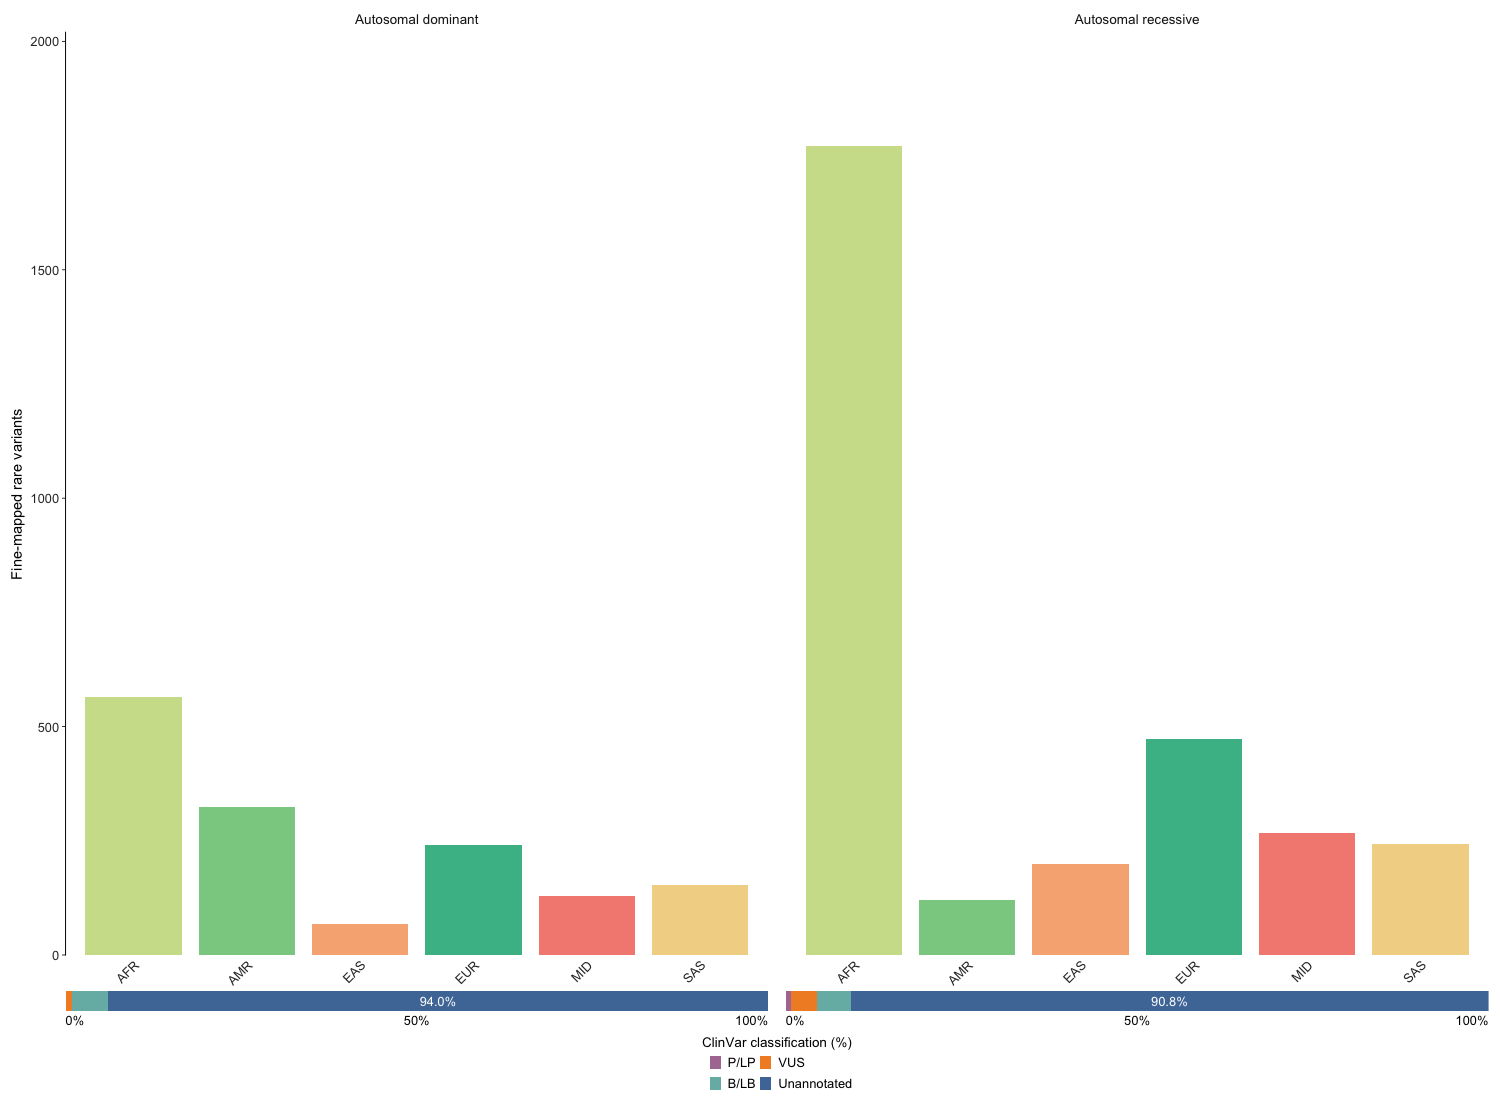

Panel A: AD = 1,480 and AR = 3,074 distinct rare variants.


In [6]:
fig5_counts <- summary$counts %>%
  mutate(total = as.double(total)) %>%
  mutate(population = factor(population, levels = fig5_populations))
fig5_proportions <- summary$proportions %>%
  mutate(clinvar_class = factor(
    clinvar_class, levels = c("P/LP", "VUS", "B/LB", "Unannotated")
  ))
fig5_mode_totals <- fig5_counts %>%
  group_by(allelicRequirements) %>%
  summarise(total = sum(total), .groups = "drop")
stopifnot(
  nrow(fig5_counts) == 12L,
  identical(fig5_mode_totals$total, c(1480, 3074)),
  all(fig5_proportions$total == if_else(
    fig5_proportions$allelicRequirements == "AD", 1480, 3074
  )),
  all(abs(fig5_proportions$proportion -
    fig5_proportions$n / fig5_proportions$total) < 1e-12)
)

fig5_A_counts <- ggplot(fig5_counts, aes(population, total, fill = population)) +
  geom_col(width = 0.85) +
  facet_grid(~allelicRequirements,
    labeller = labeller(allelicRequirements = fig5_inheritance)) +
  scale_fill_manual(values = fig5_population_palette, guide = "none") +
  scale_x_discrete(drop = FALSE, labels = str_to_upper) +
  scale_y_continuous(
    limits = c(0, 2000), breaks = seq(0, 2000, 500),
    expand = expansion(mult = c(0, 0.01))
  ) +
  labs(y = "Fine-mapped rare variants") + fig5_small_theme +
  theme(
    panel.spacing.x = grid::unit(3, "mm"),
    axis.text.x = element_text(angle = 45, hjust = 1, vjust = 1,
      size = 6.2, margin = margin(t = 2))
  )
fig5_A_classes <- ggplot(fig5_proportions) +
  geom_rect(aes(xmin = xmin, xmax = xmax, ymin = 0, ymax = 1,
    fill = clinvar_class), colour = NA) +
  geom_text(
    data = fig5_proportions %>% filter(clinvar_class == "Unannotated"),
    aes(x = (xmin + xmax) / 2, y = 0.5, label = label),
    family = "Arial", size = 6.2 / .pt, colour = "white"
  ) +
  facet_grid(~allelicRequirements) +
  scale_fill_manual(values = c(
    fig5_class_palette[c("P/LP", "VUS", "B/LB")], Unannotated = "#4E79A7"
  ), drop = FALSE) +
  scale_x_continuous(limits = c(0, 1), breaks = c(0, 0.5, 1),
    labels = scales::label_percent(accuracy = 1), expand = expansion(mult = 0)) +
  scale_y_continuous(limits = c(0, 1), expand = expansion(mult = 0)) +
  labs(x = "ClinVar classification (%)", y = NULL, fill = NULL) +
  guides(fill = guide_legend(nrow = 2, byrow = TRUE)) +
  theme_classic(base_size = 6.2, base_family = "Arial") +
  theme(
    axis.text.y = element_blank(), axis.ticks = element_blank(),
    axis.line = element_blank(),
    axis.text.x = element_text(size = 6.2, margin = margin(t = 2)),
    axis.title.x = element_text(size = 6.5, margin = margin(t = 3)),
    strip.text = element_blank(), strip.background = element_blank(),
    panel.spacing.x = grid::unit(3, "mm"), legend.position = "bottom",
    legend.text = element_text(size = 6.2),
    legend.key.width = grid::unit(2.1, "mm"),
    legend.key.height = grid::unit(2.1, "mm"),
    legend.key.spacing.x = grid::unit(0.8, "mm"),
    legend.box.spacing = grid::unit(1, "pt"),
    legend.margin = margin(1, 0, 0, 0), plot.margin = margin(0, 1, 0, 1)
  )
fig5_A <- fig5_A_counts / fig5_A_classes +
  plot_layout(heights = grid::unit(c(1, 3.5), c("null", "mm")))
# Keep the 0% and 100% labels inside their own facets, as in the archived SVG.
fig5_align_percent_labels <- function(grob) {
  if (inherits(grob, "text") &&
      identical(as.character(grob$label), c("0%", "50%", "100%"))) {
    grob$hjust <- c(0, 0.5, 1)
  }
  if (inherits(grob, "gtable")) {
    grob$grobs <- lapply(grob$grobs, fig5_align_percent_labels)
  }
  if (inherits(grob, "gTree") && length(grob$children)) {
    for (i in seq_along(grob$children)) {
      grob$children[[i]] <- fig5_align_percent_labels(grob$children[[i]])
    }
  }
  grob
}
fig5_A_grob <- fig5_align_percent_labels(patchwork::patchworkGrob(fig5_A))
fig5_A <- cowplot::ggdraw(fig5_A_grob)
save_plot(fig5_A, "Fig5_A_rebuilt", 72, 84)
print(fig5_A)
message("Panel A: AD = 1,480 and AR = 3,074 distinct rare variants.")


## Panel B: ClinVar coverage by population

This panel uses a different population assignment from panel A. A variant
is assigned to EUR if its EUR allele frequency is at least 75% of the
maximum frequency across the six populations. Other variants use the
population with the highest frequency. The overall AD and AR totals match
panel A, but some population totals differ. The dashed lines mark EUR.
The code also calculates two-sided Fisher tests for pooled non-EUR
versus EUR. The figure itself has no test labels or confidence intervals.


Export aggregate plot: Fig5_B_rebuilt


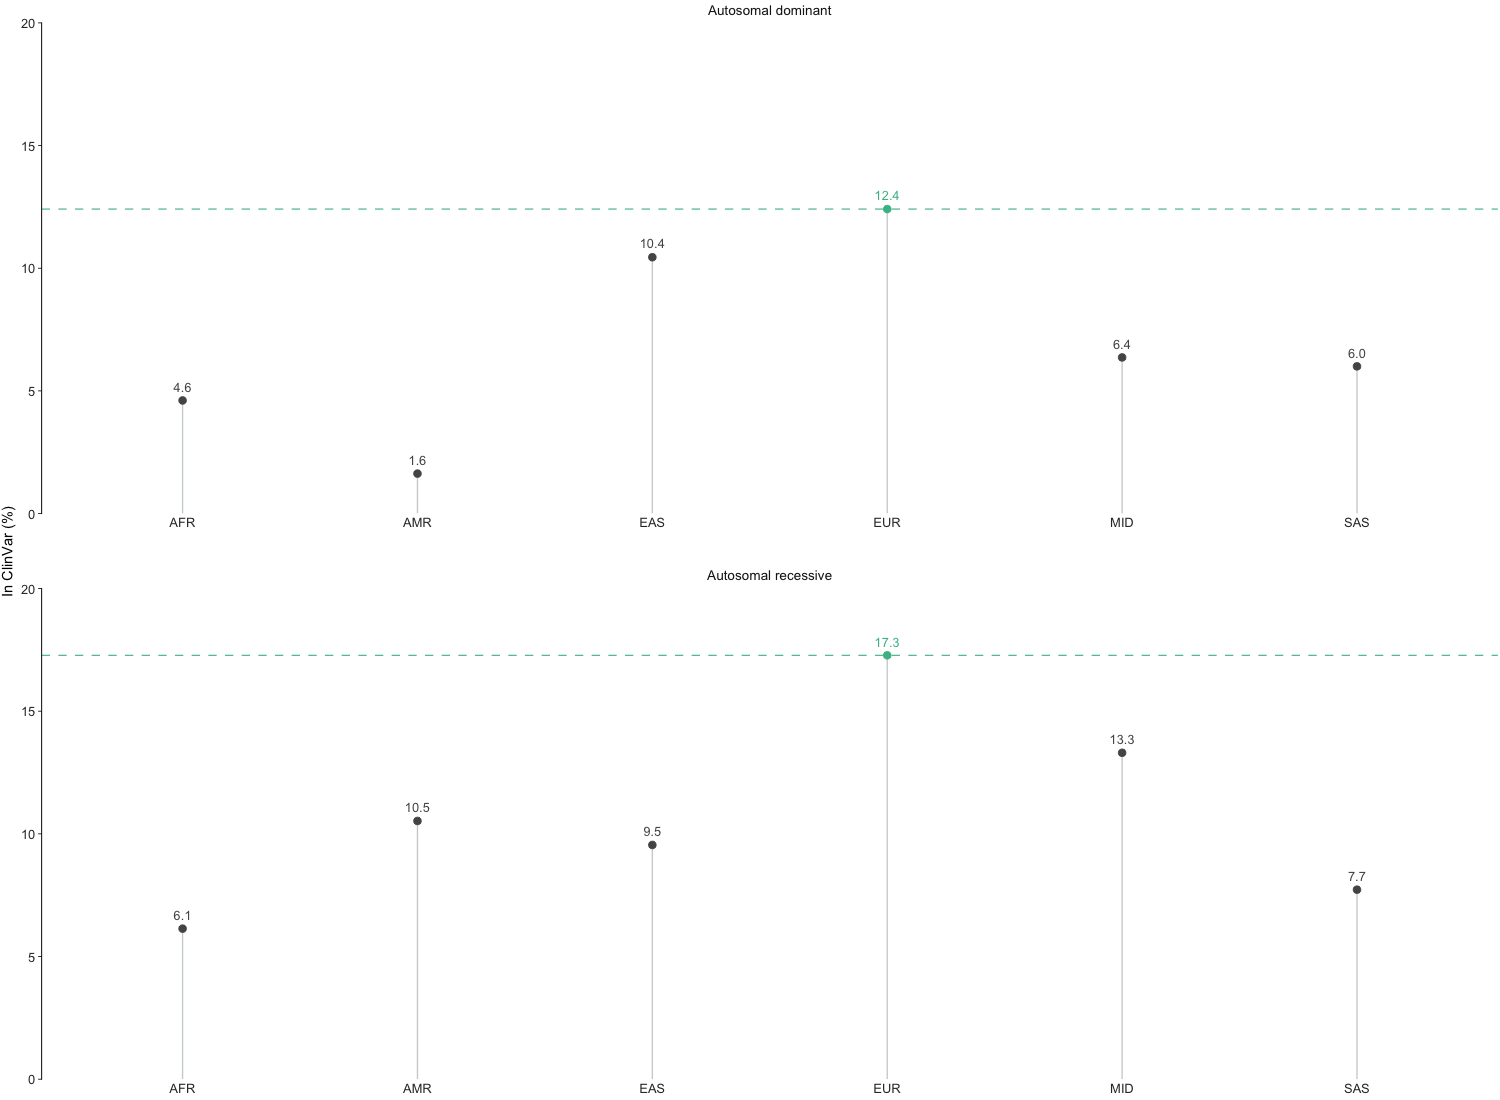

Panel B: both pooled Fisher tests use the aggregate counts.


In [7]:
fig5_coverage <- summary$coverage %>%
  mutate(population = factor(population, levels = fig5_populations),
    label = sprintf("%.1f", percent))
fig5_B_tests_computed <- coverage_tests$pooled
fig5_B_tests <- fig5_coverage %>%
  mutate(group = if_else(population == "eur", "EUR", "non_EUR")) %>%
  group_by(allelicRequirements, group) %>%
  summarise(annotated = sum(in_clinvar), unannotated = sum(total - in_clinvar),
    .groups = "drop") %>%
  group_by(allelicRequirements) %>%
  summarise(p_two_sided_rebuilt = fisher.test(cbind(
    annotated, unannotated
  ))$p.value, .groups = "drop") %>%
  left_join(fig5_B_tests_computed %>% select(allelicRequirements, p_two_sided),
    by = "allelicRequirements")
stopifnot(
  nrow(fig5_coverage) == 12L,
  all(abs(fig5_coverage$percent -
    100 * fig5_coverage$in_clinvar / fig5_coverage$total) < 1e-10),
  identical(fig5_coverage %>% group_by(allelicRequirements) %>%
    summarise(total = sum(total), .groups = "drop") %>% pull(total) %>% as.double(), c(1480, 3074)),
  all(abs(log(fig5_B_tests$p_two_sided_rebuilt /
    fig5_B_tests$p_two_sided)) < 1e-8)
)
fig5_B <- ggplot(fig5_coverage, aes(population, percent)) +
  geom_hline(data = fig5_coverage %>% filter(population == "eur"),
    aes(yintercept = percent), colour = fig5_population_palette[["eur"]],
    linetype = "dashed", linewidth = 0.25) +
  geom_segment(aes(xend = population, y = 0, yend = percent),
    colour = "#CDD1D3", linewidth = 0.3) +
  geom_point(aes(colour = emphasis), size = 1.5) +
  geom_text(aes(label = label, colour = emphasis), vjust = -1,
    size = 6.2 / .pt, family = "Arial") +
  facet_wrap(vars(allelicRequirements), ncol = 1, axes = "all_x",
    labeller = labeller(allelicRequirements = fig5_inheritance)) +
  scale_colour_manual(values = c(
    EUR = fig5_population_palette[["eur"]], `Other groups` = "#555555"
  ), guide = "none") +
  scale_y_continuous(limits = c(0, 20), breaks = seq(0, 20, 5),
    expand = expansion(mult = 0)) +
  scale_x_discrete(drop = FALSE, labels = str_to_upper) +
  labs(y = "In ClinVar (%)") + fig5_small_theme +
  theme(panel.spacing.y = grid::unit(6, "mm"))
save_plot(fig5_B, "Fig5_B_rebuilt", 45, 84)
print(fig5_B)
message("Panel B: both pooled Fisher tests use the aggregate counts.")


## Panel C: variant selection and pathogenic enrichment

The first three stages use the verified 2,928-variant starting pool.
Enrichment is the P/LP proportion at each stage divided by its proportion
in that pool. The last box counts nine AR genes. It requires a P/LP
reference and a distinct unclassified or VUS variant with high PIP.
This last search permits either effect direction. It is not a fourth
decreasing-effect filter. The selection code is shown above.


Export aggregate plot: Fig5_C_rebuilt


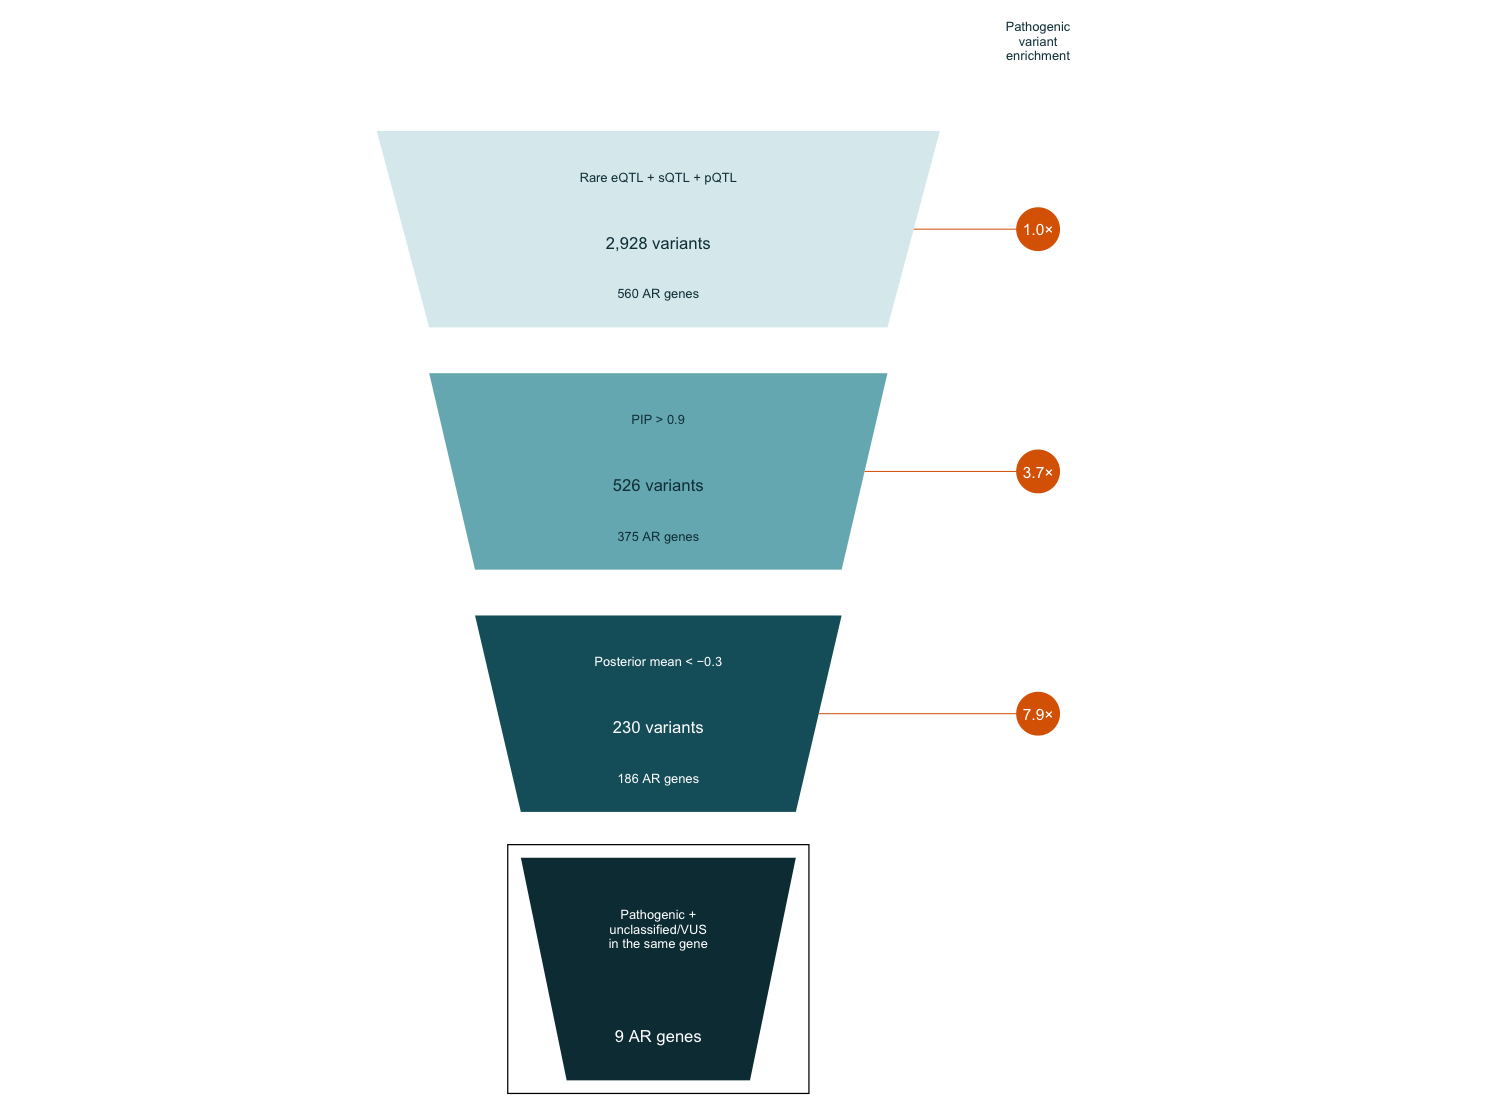

Panel C: 2,928 -> 526 -> 230 variants; final endpoint = 9 AR genes.


In [8]:
fig5_stages <- funnel$stages %>% mutate(across(where(is.integer), as.double))
fig5_verified_stages <- fig5_stages %>% slice_head(n = 3) %>%
  select(stage, variants, genes, pathogenic_variants)
fig5_stage_tests_computed <- primary
stopifnot(
  identical(fig5_stages$variants[1:3], c(2928, 526, 230)),
  identical(fig5_stages$genes, c(560, 375, 186, 9)),
  identical(fig5_stages$stage[1:3], fig5_verified_stages$stage),
  identical(fig5_stages$variants[1:3], fig5_verified_stages$variants),
  identical(fig5_stages$pathogenic_variants[1:3],
    fig5_verified_stages$pathogenic_variants)
)
fig5_stage_geometry <- tibble(
  stage = fig5_stages$stage, index = 1:4,
  ytop = c(10, 28.5, 47, 65.5), height = c(15, 15, 15, 17),
  top_width = c(43, 35, 28, 21), bottom_width = c(35, 28, 21, 14),
  colour = c("#DCECEF", "#76B5BE", "#155F6B", "#0A3943"),
  text_colour = c("#123E47", "#123E47", "white", "white")
) %>%
  left_join(fig5_stages, by = "stage") %>%
  mutate(enrichment_rebuilt = (pathogenic_variants / variants) /
    (first(pathogenic_variants) / first(variants)))
stopifnot(all(abs(fig5_stage_geometry$enrichment_rebuilt[1:3] -
  fig5_stages$enrichment[1:3]) < 1e-12))
fig5_stage_tests <- fig5_stage_geometry %>%
  filter(index %in% 2:3) %>%
  rowwise() %>%
  mutate(p_rebuilt = fisher.test(matrix(c(
    pathogenic_variants, variants - pathogenic_variants,
    21 - pathogenic_variants, 2928 - variants - (21 - pathogenic_variants)
  ), nrow = 2, byrow = TRUE))$p.value) %>%
  ungroup() %>%
  left_join(fig5_stage_tests_computed %>% select(selected_stage, p_value_two_sided),
    by = c("stage" = "selected_stage"))
stopifnot(all(abs(log(fig5_stage_tests$p_rebuilt /
  fig5_stage_tests$p_value_two_sided)) < 1e-8))
fig5_funnel_polygons <- fig5_stage_geometry %>%
  mutate(vertices = pmap(list(top_width, bottom_width, ytop, height),
    function(top_width, bottom_width, ytop, height) {
      tibble(x = 22 + c(-top_width, top_width, bottom_width, -bottom_width) / 2,
        y = ytop + c(0, 0, height, height))
    })) %>%
  select(index, colour, vertices) %>% unnest(vertices)
fig5_funnel_text <- fig5_stage_geometry %>% filter(index < 4) %>%
  mutate(filter_label = c("Rare eQTL + sQTL + pQTL", "PIP > 0.9",
    "Posterior mean < \u22120.3"),
    count_label = paste0(scales::comma(variants), " variants"),
    gene_label = paste0(genes, " AR genes"),
    enrichment_label = sprintf("%.1f\u00d7", enrichment_rebuilt))
fig5_C <- ggplot() +
  geom_polygon(data = fig5_funnel_polygons,
    aes(x, y, group = index, fill = colour), colour = NA) +
  geom_segment(data = fig5_funnel_text,
    aes(x = 22 + (top_width + bottom_width) / 4, xend = 51,
      y = ytop + 7.5, yend = ytop + 7.5),
    colour = "#DC6500", linewidth = 0.23) +
  geom_point(data = fig5_funnel_text, aes(x = 51, y = ytop + 7.5),
    colour = "#DC6500", size = 9.2) +
  geom_text(data = fig5_funnel_text,
    aes(x = 22, y = ytop + 3.5, label = filter_label, colour = text_colour),
    size = 6.2 / .pt, family = "Arial") +
  geom_text(data = fig5_funnel_text,
    aes(x = 22, y = ytop + 8.5, label = count_label, colour = text_colour),
    size = 8 / .pt, family = "Arial") +
  geom_text(data = fig5_funnel_text,
    aes(x = 22, y = ytop + 12.4, label = gene_label, colour = text_colour),
    size = 6.2 / .pt, family = "Arial") +
  geom_text(data = fig5_funnel_text,
    aes(x = 51, y = ytop + 7.5, label = enrichment_label),
    size = 7.5 / .pt, family = "Arial", colour = "white") +
  annotate("text", x = 51, y = 3.1,
    label = "Pathogenic\nvariant\nenrichment", size = 6.2 / .pt,
    family = "Arial", colour = "#123E47", lineheight = 0.95) +
  annotate("text", x = 22, y = 70.9,
    label = "Pathogenic +\nunclassified/VUS\nin the same gene",
    size = 6.2 / .pt, family = "Arial", colour = "white", lineheight = 0.95) +
  annotate("text", x = 22, y = 79.1,
    label = paste0(fig5_stages$genes[[4]], " AR genes"),
    size = 8 / .pt, family = "Arial", colour = "white") +
  annotate("rect", xmin = 10.5, xmax = 33.5, ymin = 64.5, ymax = 83.5,
    fill = NA, colour = "black", linewidth = 0.28) +
  scale_fill_identity() + scale_colour_identity() +
  scale_x_continuous(limits = c(0, 58), expand = expansion(mult = 0)) +
  scale_y_reverse(limits = c(84, 0), expand = expansion(mult = 0)) +
  coord_fixed(ratio = 1, clip = "off") + theme_void() +
  theme(plot.margin = margin(0, 0, 0, 0))
save_plot(fig5_C, "Fig5_C_rebuilt", 58, 84)
print(fig5_C)
message("Panel C: 2,928 -> 526 -> 230 variants; final endpoint = 9 AR genes.")


## Panels D and E: current REM effect displays

These tables contain the posterior mean QTL effects in the accepted plot.
Panel D has 14 variants at HEXA, PMM2, and GALM. Candidate effects have the
opposite sign to the pathogenic references. Panel E has 16 variants at six
other genes. Its candidate effects have the same sign as the references.
The plotted values are posterior effects, not log2 allelic fold changes.
Some benign comparators are common. PMM2 includes different assays, so the
effect magnitudes cannot be compared directly across all points.
The tables supply the current REM and ASJ [REM] labels. Effect direction
alone does not establish pathogenicity. No effect model is fitted here.


Export aggregate plot: Fig5_D_rebuilt


Export aggregate plot: Fig5_E_rebuilt


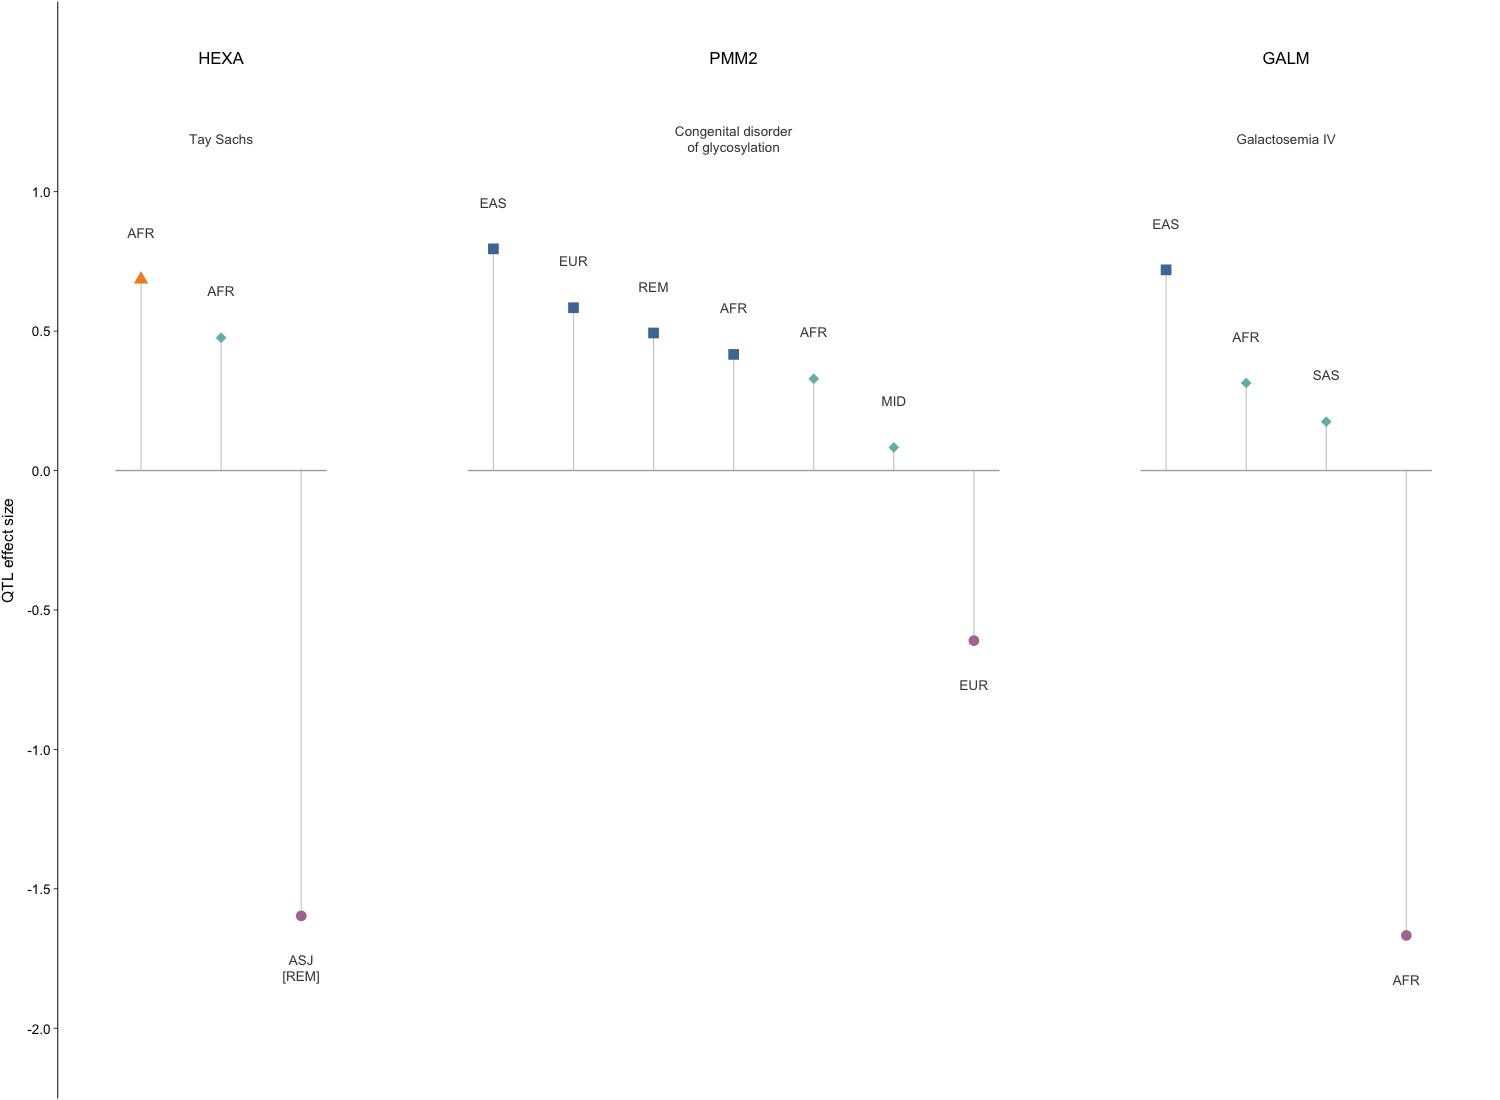

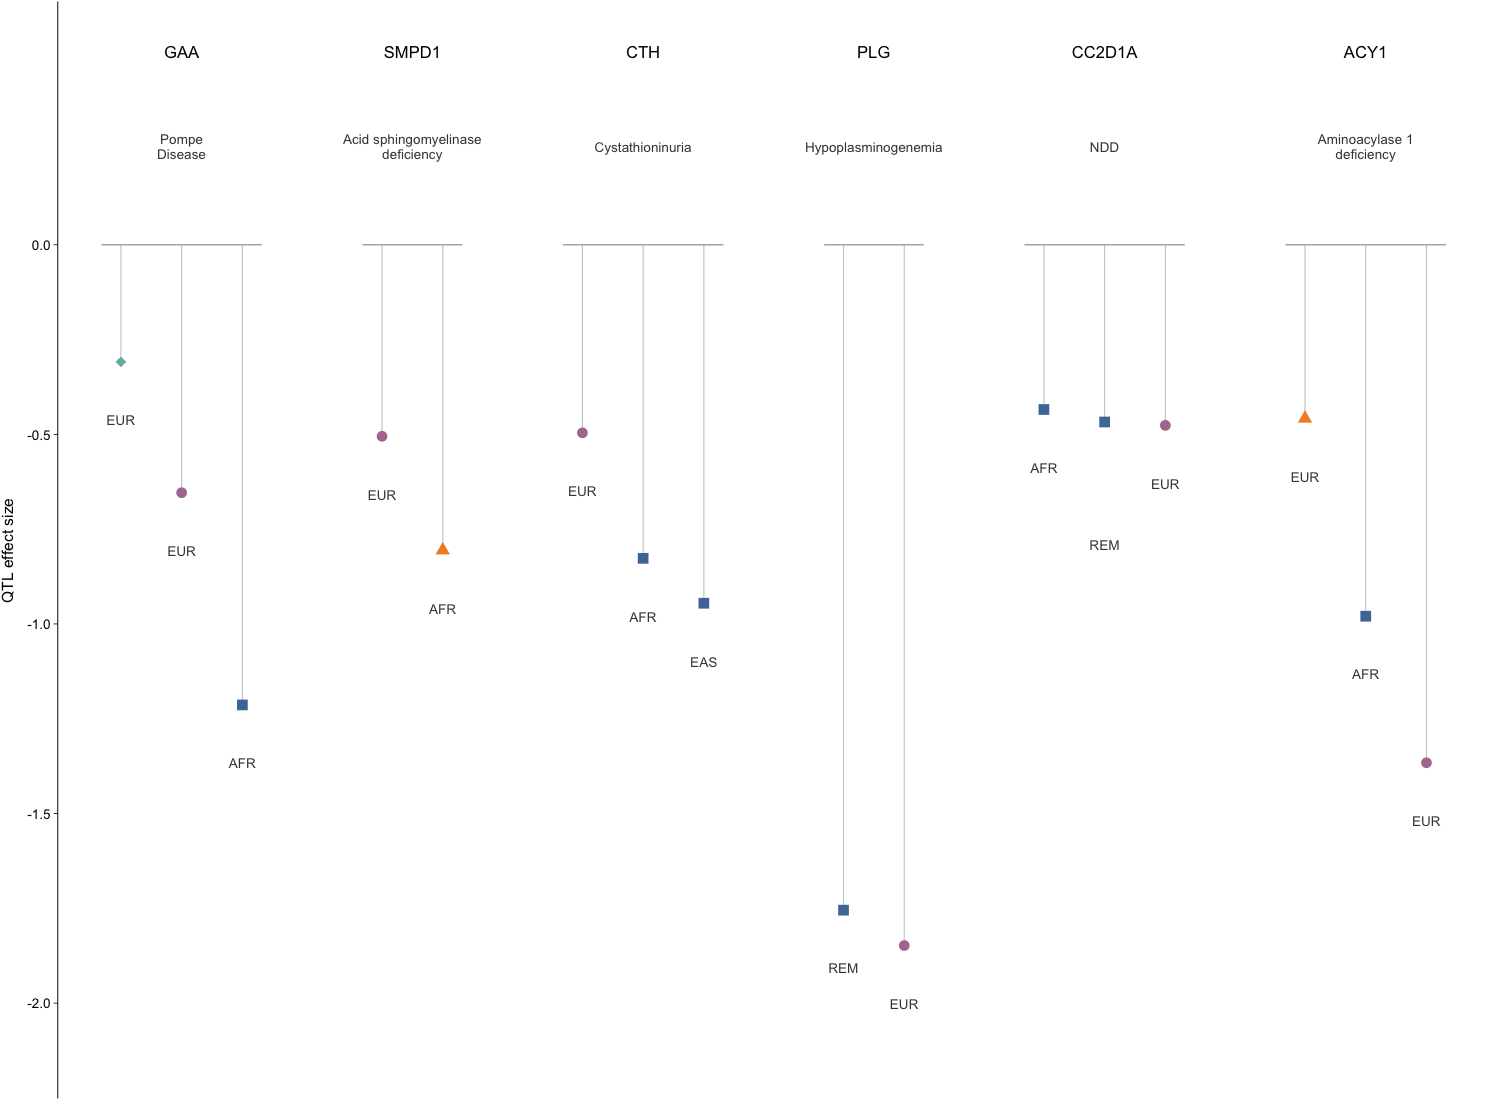

Panels D and E: all 30 effects and the four REM labels are retained.


In [9]:
fig5_D_data <- effects$D
fig5_E_data <- effects$E
stopifnot(
  nrow(fig5_D_data) == 14L, nrow(fig5_E_data) == 16L,
  n_distinct(fig5_D_data$variant) == 14L,
  n_distinct(fig5_E_data$variant) == 16L,
  all(fig5_D_data$pip > 0.9), all(fig5_E_data$pip > 0.9),
  !any(str_detect(c(fig5_D_data$ancestry, fig5_E_data$ancestry), "OTH|ADMIX")),
  sum(str_detect(c(fig5_D_data$ancestry, fig5_E_data$ancestry), "REM")) == 4L
)
fig5_make_effect_panel <- function(data, gene_order, limits, breaks,
    gene_y, disease_y) {
  display <- data %>%
    mutate(symbol = factor(symbol, levels = gene_order),
      clinvar = factor(clinvar, levels = fig5_classes))
  groups <- display %>% group_by(symbol) %>%
    summarise(xmin = min(x) - 0.32, xmax = max(x) + 0.32,
      x = mean(x), .groups = "drop") %>%
    mutate(disease = recode(as.character(symbol),
      HEXA = "Tay Sachs", PMM2 = "Congenital disorder\nof glycosylation",
      GALM = "Galactosemia IV", GAA = "Pompe\nDisease",
      SMPD1 = "Acid sphingomyelinase\ndeficiency", CTH = "Cystathioninuria",
      PLG = "Hypoplasminogenemia", CC2D1A = "NDD",
      ACY1 = "Aminoacylase 1\ndeficiency"))
  ggplot(display, aes(x, effect)) +
    geom_segment(aes(xend = x, yend = 0), colour = "#C8CDD0", linewidth = 0.25) +
    geom_segment(data = groups, aes(x = xmin, xend = xmax, y = 0, yend = 0),
      inherit.aes = FALSE, colour = "#A8B0B5", linewidth = 0.32) +
    geom_point(aes(colour = clinvar, shape = clinvar), size = 2.2) +
    geom_text(aes(y = label_y, label = ancestry,
      vjust = if_else(effect > 0, 0, 1)), family = "Arial",
      size = 6.5 / .pt, colour = "#444444", lineheight = 0.95) +
    geom_text(data = groups, aes(x, y = gene_y, label = symbol),
      inherit.aes = FALSE, family = "Arial", size = 8 / .pt) +
    geom_text(data = groups, aes(x, y = disease_y, label = disease),
      inherit.aes = FALSE, family = "Arial", size = 6.5 / .pt,
      colour = "#444444", lineheight = 0.95) +
    scale_colour_manual(values = fig5_class_palette, drop = FALSE, guide = "none") +
    scale_shape_manual(values = fig5_class_shapes, drop = FALSE, guide = "none") +
    scale_x_continuous(expand = expansion(add = 0.72)) +
    scale_y_continuous(limits = limits, breaks = breaks,
      expand = expansion(mult = 0)) +
    labs(x = NULL, y = "QTL effect size") +
    theme_classic(base_size = 7, base_family = "Arial") +
    theme(
      axis.line.x = element_blank(), axis.ticks.x = element_blank(),
      axis.text.x = element_blank(),
      axis.line.y = element_line(linewidth = 0.22),
      axis.ticks.y = element_line(linewidth = 0.18),
      axis.ticks.length = grid::unit(0.7, "mm"),
      axis.text.y = element_text(size = 6.5, colour = "black"),
      axis.title.y = element_text(size = 7.5, margin = margin(r = 4)),
      plot.margin = margin(1, 5, 1, 1), legend.position = "none"
    )
}
fig5_D <- fig5_make_effect_panel(fig5_D_data, c("HEXA", "PMM2", "GALM"),
  c(-2.25, 1.68), seq(-2, 1, 0.5), 1.48, 1.19)
fig5_E <- fig5_make_effect_panel(fig5_E_data,
  c("GAA", "SMPD1", "CTH", "PLG", "CC2D1A", "ACY1"),
  c(-2.25, 0.64), seq(-2, 0, 0.5), 0.51, 0.26)
save_plot(fig5_D, "Fig5_D_rebuilt", 182, 51)
save_plot(fig5_E, "Fig5_E_rebuilt", 182, 51)
print(fig5_D)
print(fig5_E)
message("Panels D and E: all 30 effects and the four REM labels are retained.")


## Assemble: five-panel R reconstruction

The panel positions follow the accepted 184 x 225 mm stacked layout.
Black links leave the final funnel box and point left into D and E.
This R composition rebuilds all data panels. Font metrics, text positions,
endpoint label alignment, and the funnel frame can differ from the archived


Export aggregate plot: Fig5_rebuilt_layout


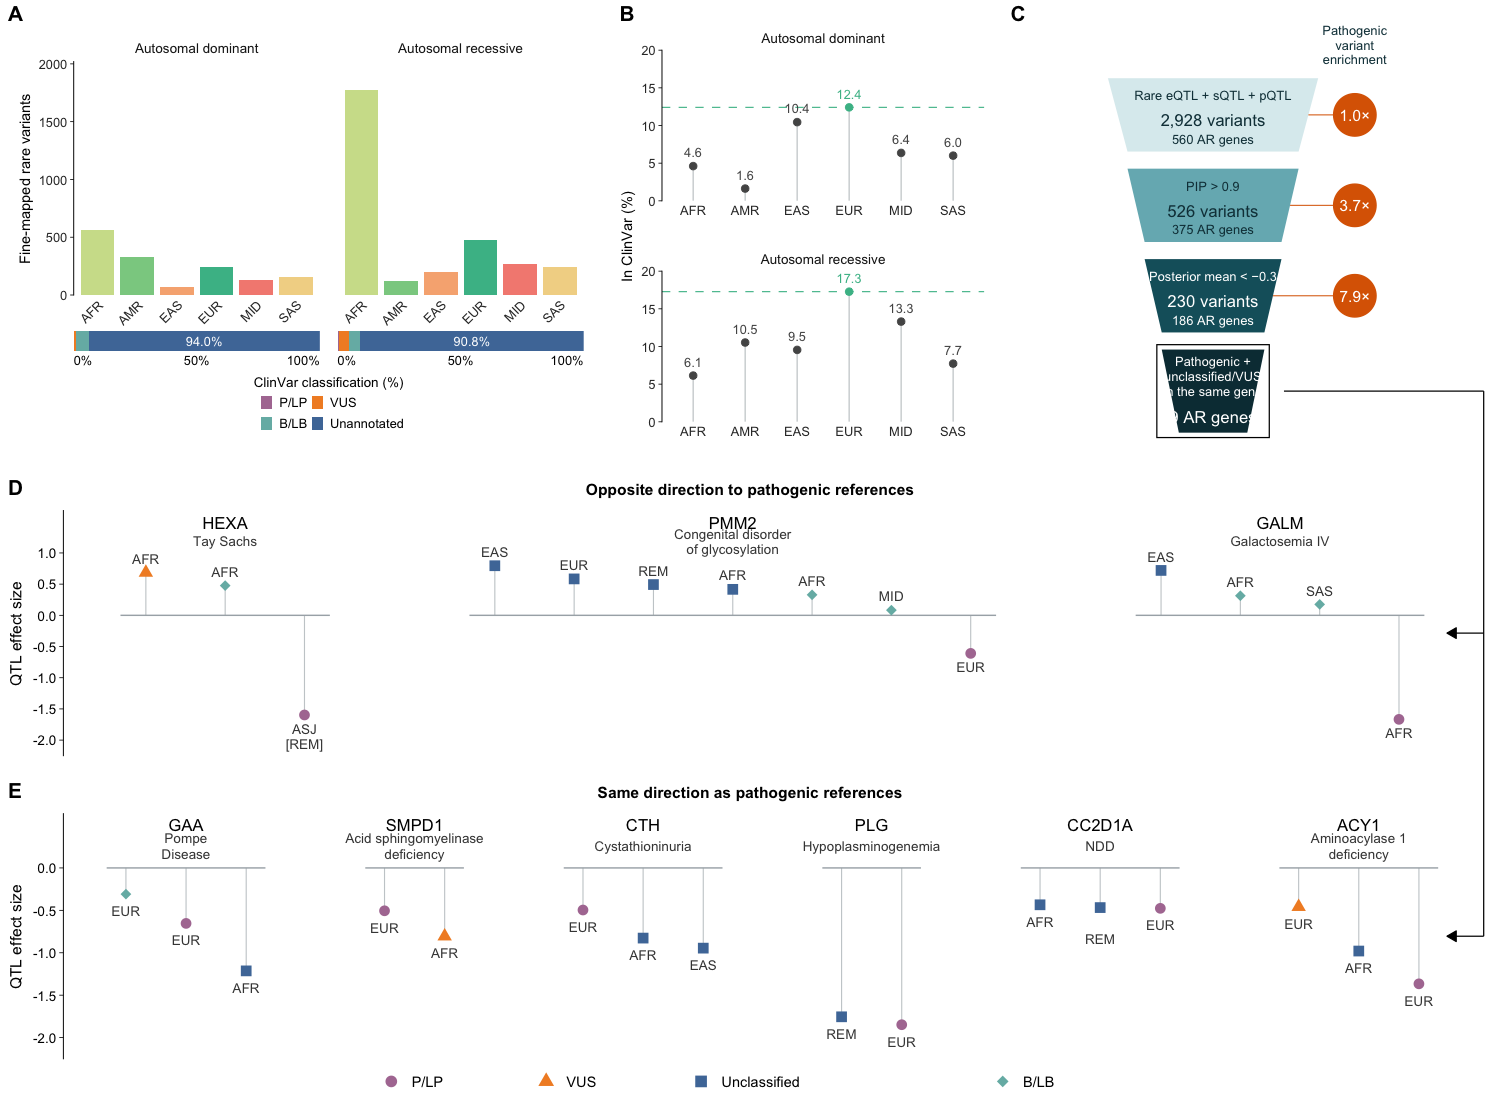

In [10]:
fig5_width_mm <- 184
fig5_height_mm <- 225
fig5_place <- function(plot, x_mm, y_mm, width_mm, height_mm) {
  cowplot::draw_plot(plot,
    x = x_mm / fig5_width_mm,
    y = 1 - (y_mm + height_mm) / fig5_height_mm,
    width = width_mm / fig5_width_mm, height = height_mm / fig5_height_mm)
}
fig5_spine <- tribble(
  ~x, ~y, ~xend, ~yend,
  157.5, 80, 182, 80,
  182, 80, 182, 191.5
)
fig5_links <- tibble(x = 182, xend = 177.5,
  y = c(129.5, 191.5), yend = c(129.5, 191.5))
fig5_legend <- tibble(
  clinvar = factor(fig5_classes, levels = fig5_classes),
  x = c(48, 67, 86, 123), y = 221.2
)
fig5_rebuilt <- cowplot::ggdraw() +
  fig5_place(fig5_A_grob, 1, 6, 72, 84) +
  fig5_place(fig5_B, 76, 6, 45, 84) +
  fig5_place(fig5_C, 124, 6, 58, 84) +
  fig5_place(fig5_D, 1, 104, 182, 51) +
  fig5_place(fig5_E, 1, 166, 182, 51) +
  geom_segment(data = fig5_spine,
    aes(x = x / fig5_width_mm, xend = xend / fig5_width_mm,
      y = 1 - y / fig5_height_mm, yend = 1 - yend / fig5_height_mm),
    inherit.aes = FALSE, linewidth = 0.28) +
  geom_segment(data = fig5_links,
    aes(x = x / fig5_width_mm, xend = xend / fig5_width_mm,
      y = 1 - y / fig5_height_mm, yend = 1 - yend / fig5_height_mm),
    inherit.aes = FALSE, linewidth = 0.28,
    arrow = grid::arrow(length = grid::unit(1.8, "mm"), type = "closed")) +
  cowplot::draw_label("A", x = 1 / 184, y = 1 - 2.7 / 225,
    hjust = 0, size = 10, fontfamily = "Arial", fontface = "bold") +
  cowplot::draw_label("B", x = 76 / 184, y = 1 - 2.7 / 225,
    hjust = 0, size = 10, fontfamily = "Arial", fontface = "bold") +
  cowplot::draw_label("C", x = 124 / 184, y = 1 - 2.7 / 225,
    hjust = 0, size = 10, fontfamily = "Arial", fontface = "bold") +
  cowplot::draw_label("D", x = 1 / 184, y = 1 - 99.7 / 225,
    hjust = 0, size = 10, fontfamily = "Arial", fontface = "bold") +
  cowplot::draw_label("E", x = 1 / 184, y = 1 - 161.7 / 225,
    hjust = 0, size = 10, fontfamily = "Arial", fontface = "bold") +
  cowplot::draw_label("Opposite direction to pathogenic references",
    x = 92 / 184, y = 1 - 100 / 225, size = 7.5,
    fontfamily = "Arial", fontface = "bold") +
  cowplot::draw_label("Same direction as pathogenic references",
    x = 92 / 184, y = 1 - 162 / 225, size = 7.5,
    fontfamily = "Arial", fontface = "bold") +
  geom_point(data = fig5_legend,
    aes(x = x / fig5_width_mm, y = 1 - y / fig5_height_mm,
      colour = clinvar, shape = clinvar), inherit.aes = FALSE, size = 2.2) +
  geom_text(data = fig5_legend,
    aes(x = (x + 2.5) / fig5_width_mm, y = 1 - y / fig5_height_mm,
      label = clinvar), inherit.aes = FALSE, size = 7 / .pt,
    family = "Arial", hjust = 0) +
  scale_colour_manual(values = fig5_class_palette, guide = "none") +
  scale_shape_manual(values = fig5_class_shapes, guide = "none")
save_plot(fig5_rebuilt, "Fig5_rebuilt_layout", fig5_width_mm, fig5_height_mm)
options(repr.plot.width = 184 / 25.4, repr.plot.height = 225 / 25.4)
print(fig5_rebuilt)
cowplot::set_null_device(fig5_previous_null_device)


## Reference figure

Complete figure layout.


Display reference Figure 5.


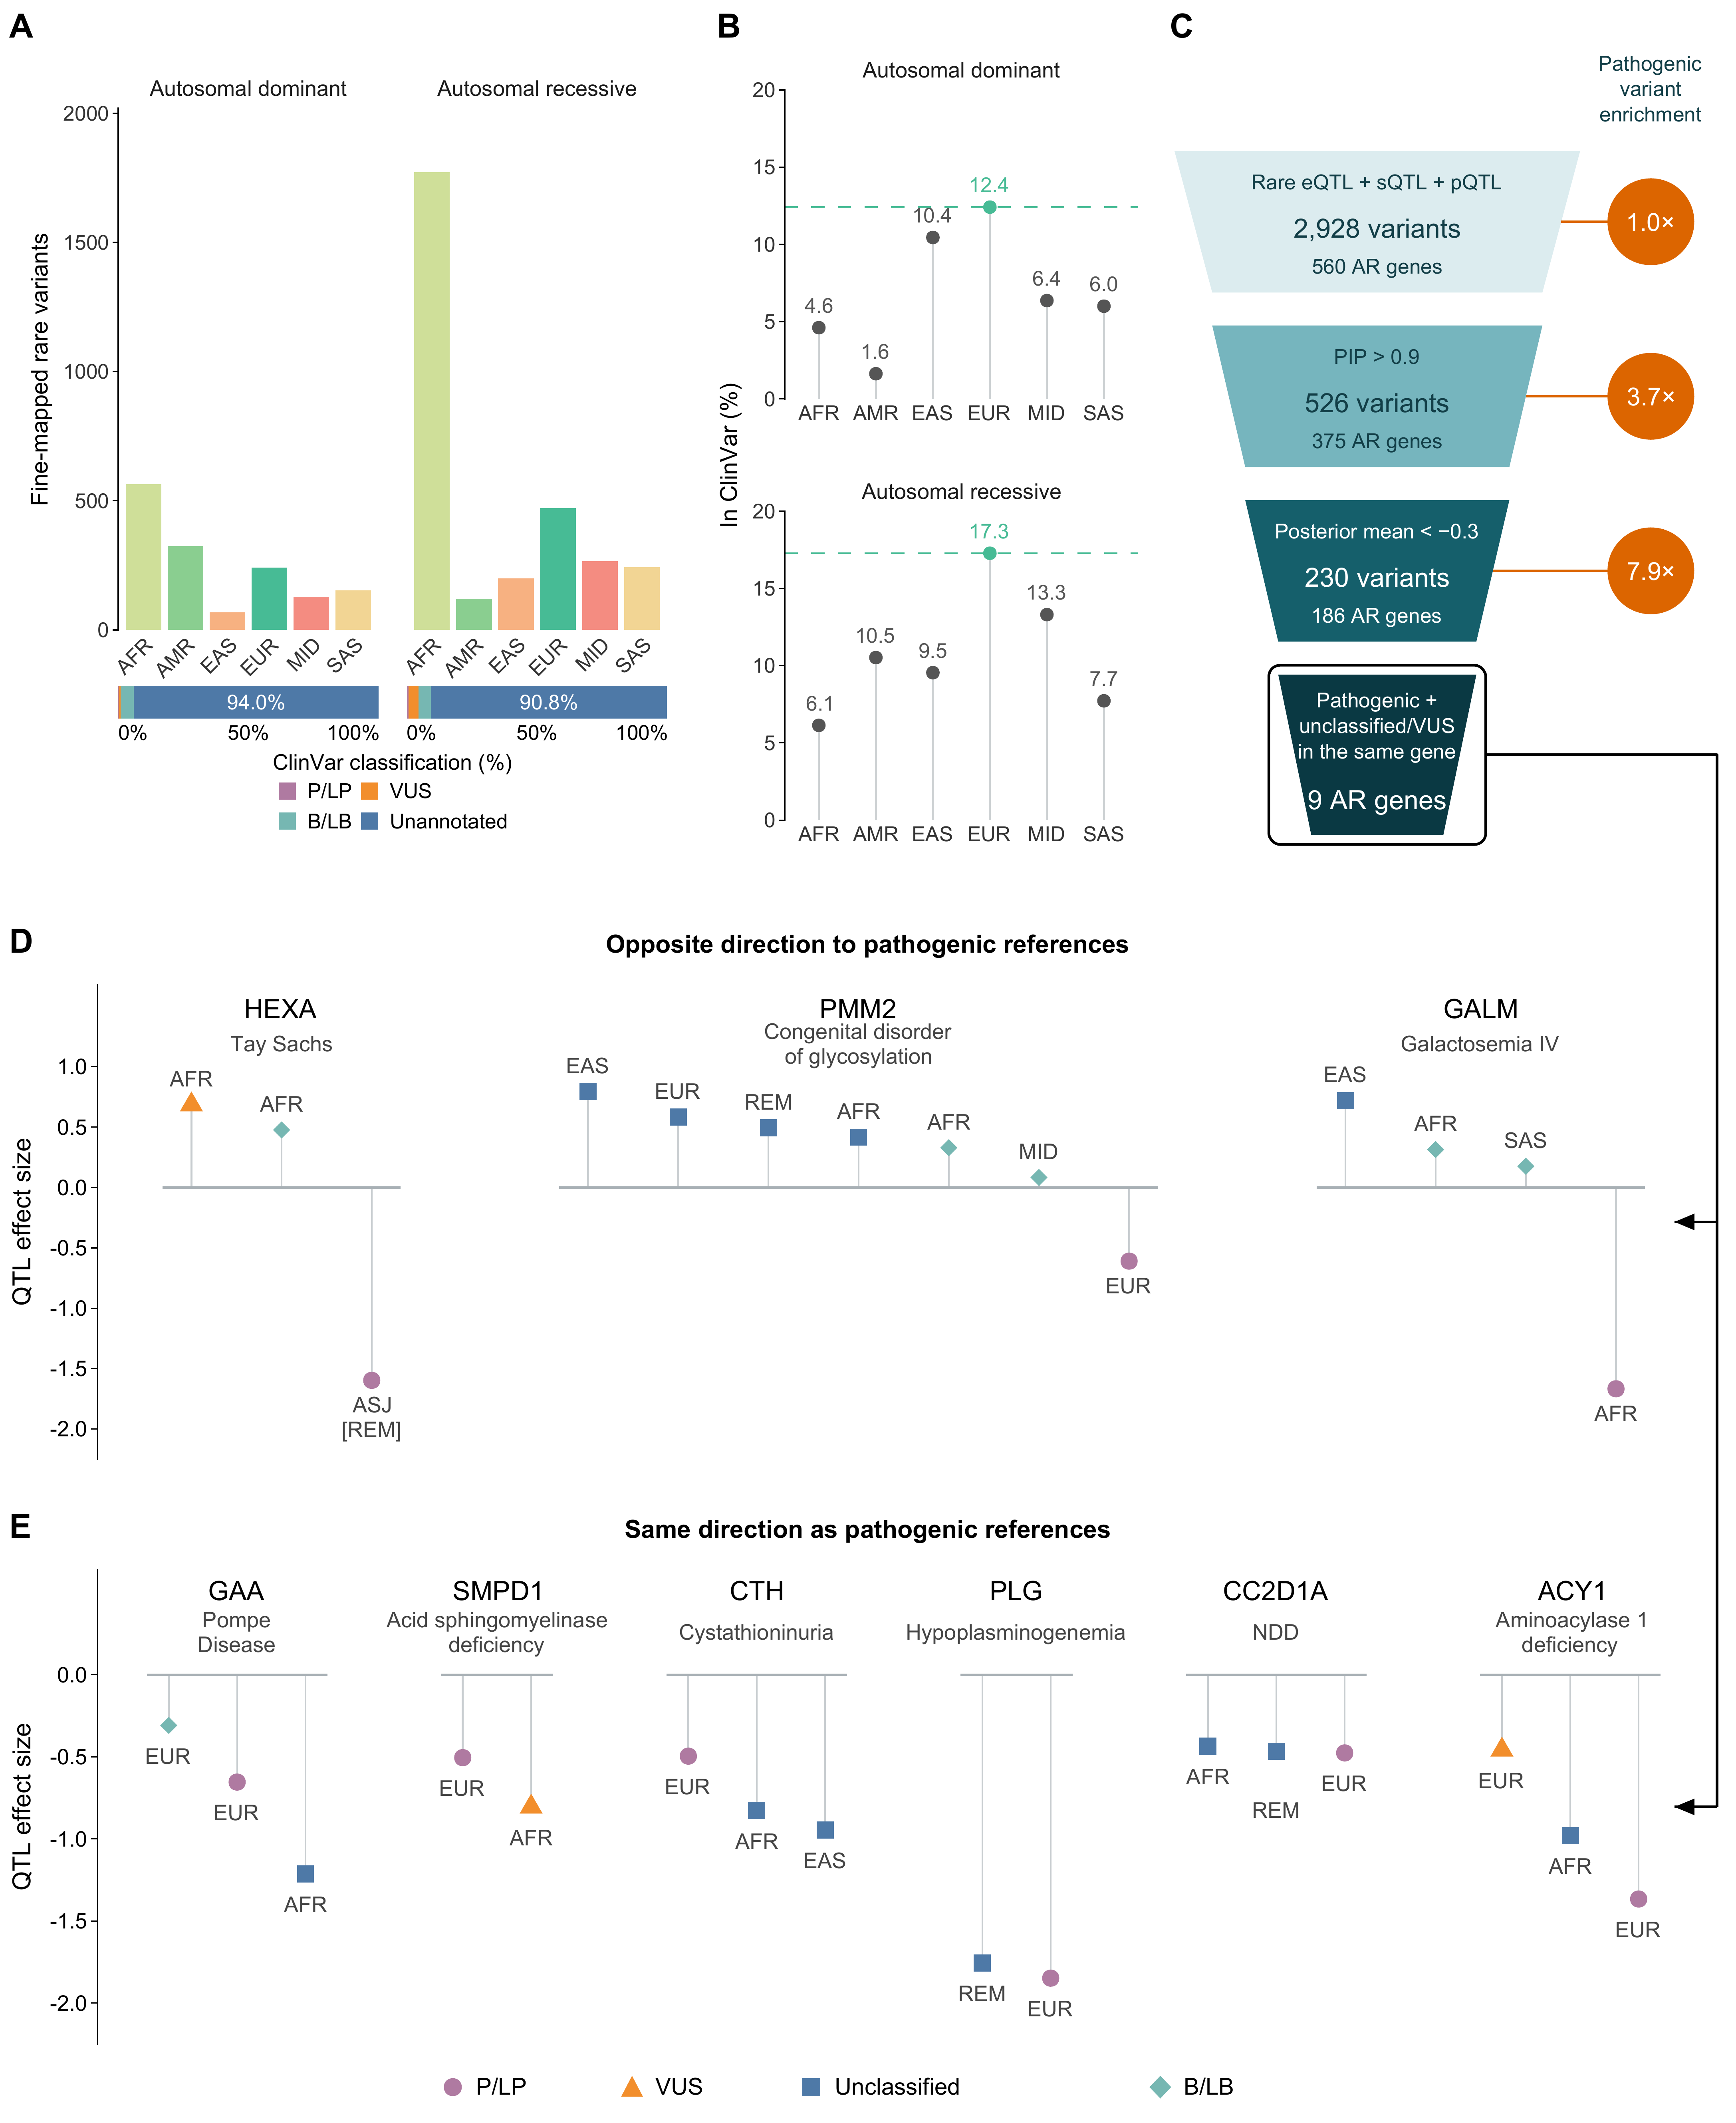

In [11]:
show_reference(5)
